# Limits on parametric amplification in photonic time crystals

**A sharp waveform bound and loss thresholds in dispersive media: computational companion**

Hitesh Kumar Singh

Department of Physics, Kurukshetra University, Kurukshetra, Haryana, India; MNS Government College, Bhiwani, Haryana, India

This notebook is the complete computational record of the study. Run from top to bottom, it regenerates every number, table entry and figure of the article from scratch: nothing is read from earlier runs. Each part opens with the theory it tests, states the algorithm, runs the computation, saves the raw results to `results/` and the figures to `figures/`, and prints the quantities quoted in the article. The last section collects all headline results.

**Running.** From the repository root, either use *Restart kernel and run all cells* or

```
jupyter nbconvert --to notebook --execute --inplace notebook.ipynb
```

A full run takes 20 to 30 minutes on one CPU core. All random draws are seeded, so repeated runs give identical results.

**Units.** We set $c = \varepsilon_0 = \mu_0 = 1$. In Part I (nondispersive media) the modulation frequency is $\Omega = 1$, so the period is $T = 2\pi$ and $k$ is measured in units of $\Omega/c$. In Part II (Lorentz media) frequencies, rates and $c k$ are measured in units of the static resonance frequency $\omega_{r0}$.

**Contents**

1. Setup
2. Study protocol
3. Theory I: Hill equation and the total-variation bound
4. Validation of the Hill solver
5. H1: the bound on the protocol ensemble
6. Extended waveform ensemble and the operator-norm form
7. H3: attainability by two-level switching, and the uncertainty budget
8. H2: efficiency of harmonic modulation
9. Theory II: lossy Lorentz medium
10. Validation of the Lorentz solver
11. H4a: net rates on the lower polariton branch
12. Interbranch crossings
13. Upper polariton branch
14. The rate ceiling
15. Thresholds and the growth inequality (H4b)
16. H4c: gap width and net rate along the resonance path
17. Summary of results

## 1. Setup

The reusable numerical code lives in three modules under `src/`:

* `hill.py`: modulation waveforms, exact total variation, Hill monodromy, energy norm, exact transfer matrices for sudden switching;
* `lorentz.py`: polariton branches, participation factors, Floquet monodromy of the modulated Lorentz medium, four-mode secular theory, the integrated growth inequality;
* `figstyle.py`: the common figure style and an automatic layout check that refuses to save a figure whose text overlaps, is clipped, or sits inside the plotting region.

Everything specific to one experiment (grids, loops, statistics, figures) is written out below, so the notebook can be read without opening other files.

In [1]:
import json
import math
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter, NullLocator
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, differential_evolution, minimize, minimize_scalar
from scipy.special import mathieu_a, mathieu_b

ROOT = Path.cwd()
assert (ROOT / "src" / "hill.py").exists(), "start the notebook from the repository root"
sys.path.insert(0, str(ROOT / "src"))

import figstyle as fs  # noqa: E402
import hill  # noqa: E402
import lorentz as L  # noqa: E402

%config InlineBackend.figure_formats = ["png"]
plt.rcParams["figure.dpi"] = 110

RESULTS, FIGURES = ROOT / "results", ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)


def plain(x):
    # Convert NumPy scalars and arrays so that results can be written as JSON.
    if isinstance(x, dict):
        return {str(k): plain(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [plain(v) for v in x]
    if isinstance(x, np.ndarray):
        return plain(x.tolist())
    if isinstance(x, np.bool_):
        return bool(x)
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, np.floating):
        return float(x)
    return x


def save_json(name, payload):
    (RESULTS / name).write_text(json.dumps(plain(payload), indent=1) + "\n")


def show(fig, stem):
    # Layout check, then PDF and 600 dpi PNG in figures/, then inline display.
    fs.save(fig, FIGURES / stem)
    display(fig)
    plt.close(fig)


summary = {}       # headline numbers, written to results/summary.json in Sec. 17
t_start = time.perf_counter()
print(f"Python {platform.python_version()} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"Matplotlib {matplotlib.__version__} | SymPy {sp.__version__}")

Python 3.13.16 | NumPy 2.4.4 | SciPy 1.17.1 | Matplotlib 3.10.8 | SymPy 1.14.0


## 2. Study protocol

The hypotheses, tolerances, grids and benchmarks below were fixed in writing before any production run. They are reproduced here because the article reports each criterion as registered, including the one that failed.

| Item | Statement | Criterion |
|---|---|---|
| H1 | For every $T$-periodic $\varepsilon(t)>0$ in the test classes and every $k$, $\mu T \le \tfrac14\,\mathrm{TV}_T[\ln\varepsilon]$ | no violation beyond $\mathrm{tol}_{\rm num} = 10^{-8} + 3\sigma_{\rm solver}$ |
| H2 | Harmonic modulation reaches $\pi/4$ of the bound at the first-tongue center | ratio within $\pm 2\%$ of $\pi/4$ for $\delta \le 0.02$ |
| H3 | Optimized two-switch profiles approach the bound as the ramp width $w \to 0$ | saturation $\ge 0.99$ for $\varepsilon_2/\varepsilon_1 \in \{1.2, 2, 4\}$ |
| H4a | The two-mode net exponent of Sec. 9.3 predicts the Floquet exponent | within 10% for $m \le 0.05$, $\gamma \le 0.03$, both channels, across the $k$ grid |
| H4b | The growth inequality of Sec. 9.2, integrated along trajectories, is never violated | beyond $\mathrm{tol}_{\rm num}$ |
| H4c | Along the resonance path $P^*$ the momentum gap widens while the net rate does not keep pace | width factor $> 3$ and rate factor $< 1.5$ |

**Benchmarks**, required before production: B1 constant $\varepsilon$ gives $|\mu| < 10^{-10}$; B2 Mathieu tongue-center rate within 3% of $\delta\omega_k/4$ at $\delta = 0.02$; B2b tongue edges against Mathieu characteristic values to relative $10^{-6}$; B3 sudden temporal interface amplitudes against the analytic coefficients to $10^{-6}$; B4 energy-angle identity residual $< 10^{-8}$ per period; B5 static polariton multipliers against the roots of the dispersion quartic to $10^{-9}$ (lossless) and $10^{-8}$ (lossy); B6 Lorentz solver reduces to the Hill solver as $\omega_p \to 0$ to $10^{-8}$.

**Fixed numerical settings.** DOP853 integration with relative tolerance $10^{-11}$ and absolute tolerance $10^{-13}$; $\sigma_{\rm solver}$ is the largest change of $\mu T$ between tolerances $10^{-9}$ and $10^{-13}$ over a 20-case probe; the ensemble E1 has 400 log-Fourier profiles (seed 12345) on 60 wavevectors; the dispersive scan E2 uses $\omega_{r0} = 1$, $\omega_{p0} = 0.8$, $\gamma \in \{10^{-3}, 3\times10^{-3}, 10^{-2}, 3\times10^{-2}\}$, $m \in \{0.01, 0.02, 0.05, 0.1\}$ and 80 wavevectors with the drive tracking the tongue center.

**Deviations from the protocol**, all reported in the article:

1. The registered path $P^*$ (half drive frequency from $1.6\,\omega_{r0}$ to $1.05\,\omega_{r0}$ on the lower branch) is internally inconsistent, because lower-branch frequencies never exceed $\omega_{r0}$. Before the dispersive runs it was replaced by the detuning path $1 - \omega/\omega_{r0}$ from 0.40 to 0.01 in 12 logarithmic steps, with unchanged criteria.
2. H4a is evaluated with the exponent of the parametrically coupled multiplier pair (multipliers nearest $-1$), the quantity the two-mode theory describes. The largest exponent of the full system is stored as well.
3. The total variation is evaluated exactly at the turning points of $\ln\varepsilon$ instead of by dense quadrature, and every Hill integration caps the step size at a fraction of the fastest feature of the waveform, so that adaptive steps cannot skip a narrow ramp; Sec. 7.4 quantifies the step and tolerance components of the error.
4. Analyses added after the registered runs are labeled *post hoc* wherever they appear: the extended waveform ensemble and the operator-norm test (Sec. 6), the exact sudden-switching optimum (Sec. 7.1), the depth sweep of the harmonic efficiency (Sec. 8.2), the four-mode theory of the interbranch crossings (Sec. 12), the upper branch (Sec. 13) and the ceiling across media (Sec. 14).
5. The registered exploratory item E3 (a rotation-number check) was not carried out; no result depends on it.

# Part I. Nondispersive photonic time crystals

## 3. Theory I: Hill equation and the total-variation bound

### 3.1 Hill equation and Floquet exponents

Consider a spatially uniform, nonmagnetic medium whose relative permittivity $\varepsilon(t) > 0$ is periodic with period $T = 2\pi/\Omega$. For a plane wave $e^{ikx}$ Maxwell's equations read $\dot D = -ikH$ and $\dot H = -ikE$ with $D = \varepsilon(t)E$, so the displacement obeys the Hill equation

$$\ddot D + \omega(t)^2 D = 0, \qquad \omega(t)^2 = \frac{k^2}{\varepsilon(t)} .$$

$D$ and $\dot D \propto B$ are continuous even where $\varepsilon$ jumps. The monodromy matrix $M$ maps $(D, \dot D)$ at $t = 0$ to its value at $t = T$. Because the generator is traceless, $\det M = 1$ exactly (the Wronskian is conserved), and the multipliers come in pairs $\lambda, 1/\lambda$. A wavevector lies in a momentum gap when $|\mathrm{tr}\,M| > 2$; the field then grows as $|\lambda_{\max}|^{t/T}$, and we define the amplitude exponent $\mu = \ln|\lambda_{\max}|/T$.

### 3.2 Energy-angle identity and Theorem 1

Write a real solution as $D = \sqrt{2E}\,\sin\theta/\omega$ and $\dot D = \sqrt{2E}\,\cos\theta$, where $E = \tfrac12(\dot D^2 + \omega^2 D^2)$ is the instantaneous Hill energy. Differentiating and using the Hill equation gives

$$\frac{d\ln E}{dt} = \frac{\dot\omega}{\omega}\,\bigl(1 - \cos 2\theta\bigr).$$

The first term integrates to $\ln\omega(T) - \ln\omega(0) = 0$. Hence, for every initial condition,

$$\ln\frac{E(T)}{E(0)} = -\int_0^T \frac{\dot\omega}{\omega}\cos 2\theta\,dt \;\le\; \int_0^T\Bigl|\frac{d\ln\omega}{dt}\Bigr|\,dt = \mathrm{TV}_T[\ln\omega] = \tfrac12\,\mathrm{TV}_T[\ln\varepsilon].$$

**Theorem 1.** For every $k$ and every $T$-periodic $\varepsilon(t) > 0$ of bounded variation (jumps included),

$$\|M\|_E \le \exp\Bigl(\tfrac14\,\mathrm{TV}_T[\ln\varepsilon]\Bigr), \qquad \mu T \le \tfrac14\,\mathrm{TV}_T[\ln\varepsilon] .$$

Here $\|\cdot\|_E$ is the operator norm induced by the energy norm $\sqrt{2E}$ at $t = 0$, which coincides with the energy norm at $t = T$ because $\omega(T) = \omega(0)$. The per-period inequality holds uniformly in the initial phase, which gives the operator-norm statement; the exponent statement follows because the spectral radius never exceeds an operator norm. No averaging along a dominant solution is needed.

### 3.3 Attainability

Equality requires $\cos 2\theta = -\operatorname{sgn}\dot\omega$ wherever $\omega$ changes: $\omega$ must rise when $D$ is at an extremum ($\theta = \pi/2$) and fall when $D$ passes through zero ($\theta = 0$). A smooth modulation cannot keep this phase relation over finite intervals, but sudden switching between two levels can. If each level is held for a quarter of its own oscillation period, $t_i = \pi/(2\omega_i)$ with $\omega_i = k/\sqrt{\varepsilon_i}$, every jump meets the field at the right phase. With $t_1 + t_2 = T$ this fixes

$$k^\ast = \frac{\Omega}{4}\bigl(\sqrt{\varepsilon_1} + \sqrt{\varepsilon_2}\bigr), \qquad \frac{t_2}{T} = \frac{\sqrt{\varepsilon_2}}{\sqrt{\varepsilon_1} + \sqrt{\varepsilon_2}} ,$$

and the multiplier is $|\lambda| = \sqrt{\varepsilon_{\max}/\varepsilon_{\min}} = \exp(\mathrm{TV}_T[\ln\varepsilon]/4)$: the bound is attained exactly. This is the parametric mechanism of a pumped swing. Smoothed switching with ramp width $w$ approaches the bound as $w \to 0$.

### 3.4 Harmonic modulation

For $\varepsilon = 1 + \delta\cos\Omega t$ the first tongue is centered at $\Omega = 2\omega_k$ with $\omega_k = k$, where the Mathieu growth rate is $\mu = \delta\omega_k/4$ to leading order, i.e. $\mu T = \pi\delta/4$. The bound gives $\tfrac14\,\mathrm{TV}_T[\ln\varepsilon] = \tfrac12\ln\frac{1+\delta}{1-\delta} = \delta + O(\delta^3)$. Harmonic driving therefore reaches $\pi/4 \approx 0.785$ of the limit at leading order. Sections 8.1 and 8.2 test this at the registered depths and far beyond them.

### 3.5 Algorithms

* **Monodromy.** The two columns of the identity are propagated over one period with the eighth-order Runge-Kutta method DOP853 (relative tolerance $10^{-11}$, absolute $10^{-13}$). Adaptive step control alone can step across a narrow ramp, so the step is capped at $T/(20 N_h)$ for a profile with $N_h$ harmonics and at half the ramp width for two-level profiles.
* **Exponent and energy norm.** $\mu T = \ln\max|\lambda_i(M)|$; $\|M\|_E = \|SMS^{-1}\|_2$ with $S = \mathrm{diag}(\omega(0), 1)$.
* **Total variation.** $\ln\varepsilon$ is monotone between consecutive zeros of its derivative, so $\mathrm{TV}_T$ is the sum of $|\Delta\ln\varepsilon|$ over those monotone runs. Zeros are bracketed on a grid that is refined until the bracket count is stable, then located with Brent's method. The result is exact to round-off.
* **Audit.** Every production monodromy is checked against $\det M = 1$.

## 4. Validation of the Hill solver

The benchmarks B1 to B4 test the integrator against cases with known answers. B2b and B3 use their own short right-hand sides because they test the integrator on equations that are not of the form $\omega^2 = k^2/\varepsilon(t)$ (the standard Mathieu equation) or that are not periodic (a single temporal interface).

In [2]:
validation_hill = {}

# B1: constant permittivity, multipliers on the unit circle
b1 = max(abs(hill.floquet_exponent(hill.SinusoidWaveform(delta=0.0), k)) for k in (0.3, 0.7, 1.3))
validation_hill["B1_max_abs_mu"] = b1

# B2: Mathieu tongue-center rate, delta = 0.02, leading order delta * omega_k / 4
wf = hill.SinusoidWaveform(delta=0.02)
mu_b2 = max(hill.floquet_exponent(wf, k) for k in np.linspace(0.499, 0.501, 11))
validation_hill["B2_relative_error"] = abs(mu_b2 - 0.02 * 0.5 / 4) / (0.02 * 0.5 / 4)


# B2b: edges of the first tongue of y'' + w0^2 (1 + h cos 2t) y = 0 against the
# Mathieu characteristic values a_1(q), b_1(q) with a = w0^2, q = w0^2 h / 2
def mathieu_trace(w0, h):
    def rhs(t, y):
        return [y[1], -(w0 * w0) * (1.0 + h * math.cos(2.0 * t)) * y[0],
                y[3], -(w0 * w0) * (1.0 + h * math.cos(2.0 * t)) * y[2]]
    y = solve_ivp(rhs, (0.0, math.pi), [1.0, 0.0, 0.0, 1.0], method="DOP853",
                  rtol=1e-11, atol=1e-13).y[:, -1]
    return y[0] + y[3]


h = 0.1
f_edge = lambda w0: abs(mathieu_trace(w0, h)) - 2.0
grid = np.linspace(0.93, 1.07, 41)
vals = [f_edge(g) for g in grid]
edges = sorted(brentq(f_edge, grid[i], grid[i + 1], xtol=1e-12)
               for i in range(len(grid) - 1) if vals[i] * vals[i + 1] < 0)
theory = sorted([brentq(lambda w0: w0 * w0 - mathieu_a(1, w0 * w0 * h / 2), 0.9, 1.1, xtol=1e-12),
                 brentq(lambda w0: w0 * w0 - mathieu_b(1, w0 * w0 * h / 2), 0.9, 1.1, xtol=1e-12)])
assert len(edges) == 2
validation_hill["B2b_max_relative_edge_error"] = max(abs(a - b) / b for a, b in zip(edges, theory))


# B3: sudden step eps1 -> eps2; D and D' continuous give forward and backward
# amplitudes A = (1 + w1/w2)/2 and B = (1 - w1/w2)/2. A tanh step of width tau is
# integrated and the O(tau^2) error removed by Richardson extrapolation.
def interface_amplitudes(tau, eps1=1.0, eps2=2.25, k=1.0):
    w1, w2 = k / math.sqrt(eps1), k / math.sqrt(eps2)
    epsf = lambda t: eps1 + (eps2 - eps1) * 0.5 * (1.0 + math.tanh(t / tau))
    t0, t1 = -9.0 * tau, 9.0 * tau
    y0 = [np.exp(-1j * w1 * t0), -1j * w1 * np.exp(-1j * w1 * t0)]
    D, Dd = solve_ivp(lambda t, y: [y[1], -(k * k / epsf(t)) * y[0]], (t0, t1), y0,
                      method="DOP853", rtol=1e-12, atol=1e-14).y[:, -1]
    A = 0.5 * (D + 1j * Dd / w2) * np.exp(1j * w2 * t1)
    B = 0.5 * (D - 1j * Dd / w2) * np.exp(-1j * w2 * t1)
    return abs(A), abs(B)


(A1, B1), (A2, B2) = interface_amplitudes(0.010), interface_amplitudes(0.005)
A_ext, B_ext = (4 * A2 - A1) / 3, (4 * B2 - B1) / 3
validation_hill["B3_amplitude_errors"] = [abs(A_ext - 1.25), abs(B_ext - 0.25)]

# B4: energy-angle identity along trajectories
validation_hill["B4_max_residual"] = max(
    hill.energy_angle_residual(hill.SinusoidWaveform(delta=0.04), k) for k in (0.42, 0.5, 0.9))

# Exact total variation against closed forms
tv_errors = [abs(hill.total_variation(hill.SinusoidWaveform(delta=d)) - 2 * math.log((1 + d) / (1 - d)))
             for d in (0.05, 0.4, 0.85)]
tv_errors.append(abs(hill.total_variation(hill.LogFourierWaveform(np.array([0.3]), np.array([0.7]))) - 1.2))
tv_errors.append(abs(hill.total_variation(hill.TwoLevelWaveform(1.0, 3.0, 0.2, 0.7, 0.02)) - 2 * math.log(3.0)))
validation_hill["TV_max_abs_error"] = max(tv_errors)

checks = {"B1_max_abs_mu": 1e-10, "B2_relative_error": 0.03, "B2b_max_relative_edge_error": 1e-6,
          "B4_max_residual": 1e-8, "TV_max_abs_error": 1e-9}
for key, tol in checks.items():
    assert validation_hill[key] < tol, key
assert max(validation_hill["B3_amplitude_errors"]) < 1e-6
for key, value in validation_hill.items():
    print(f"{key:30s} {np.max(value):.2e}")

B1_max_abs_mu                  8.05e-14
B2_relative_error              3.83e-05
B2b_max_relative_edge_error    4.20e-13
B3_amplitude_errors            6.10e-10
B4_max_residual                4.88e-10
TV_max_abs_error               1.22e-10


**Solver uncertainty.** The registered definition of $\sigma_{\rm solver}$ is the largest change of $\mu T$ when the tolerances are tightened from $10^{-9}$ to $10^{-13}$, over 20 cases: the first ten profiles of the protocol ensemble at $k = 0.45$ and $k = 0.5$. It enters the violation tolerance $\mathrm{tol}_{\rm num} = 10^{-8} + 3\sigma_{\rm solver}$. The step-placement component, which dominates for sharp ramps, is measured in Sec. 7.4 on the profile that carries the saturation result.

In [3]:
probe = hill.random_log_fourier(10, seed=12345)
sigma_solver = max(abs(hill.floquet_exponent(wf, k, rtol=1e-9, atol=1e-11)
                       - hill.floquet_exponent(wf, k, rtol=1e-13, atol=1e-15)) * wf.T
                   for wf in probe for k in (0.45, 0.5))
TOL_NUM = 1e-8 + 3 * sigma_solver
validation_hill.update(sigma_solver_muT=sigma_solver, tol_num=TOL_NUM)
save_json("validation_hill.json", validation_hill)
summary["sigma_solver"] = sigma_solver
summary["tol_num"] = TOL_NUM
summary["benchmarks_hill"] = {k: float(np.max(v)) for k, v in validation_hill.items()}
print(f"sigma_solver = {sigma_solver:.2e}   tol_num = {TOL_NUM:.4e}")

sigma_solver = 1.77e-15   tol_num = 1.0000e-08


## 5. H1: the bound on the protocol ensemble

The registered test classes are (a) 400 random log-Fourier profiles

$$\varepsilon(t) = \exp\Bigl(\sum_{n=1}^{6} a_n\cos(n\Omega t + \phi_n)\Bigr), \qquad a_n \sim \mathcal U(-0.35, 0.35)/n,\quad \phi_n \sim \mathcal U(0, 2\pi),$$

drawn with seed 12345 and kept when the permittivity contrast $\max\varepsilon/\min\varepsilon$ is at most 4; (b) smoothed two-level profiles with ramp widths $w/T \in \{0.05, 0.02, 0.01, 0.005\}$; (c) sinusoids with $\delta \in \{0.005, 0.01, 0.02, 0.04\}$. Each profile is scanned over 60 wavevectors $k \in [0.3, 1.8]$, which cover the first three tongues. For class (b) we use the three contrasts of H3 and the dwell fraction of Sec. 3.3, the most demanding choice because it places the profiles close to saturation.

For every monodromy we record the exponent, the energy-norm growth $\ln\|M\|_E$ and the Wronskian error $|\det M - 1|$.

In [4]:
K_E1 = np.linspace(0.3, 1.8, 60)


def scan_waveform(wf, kk):
    # Columns: mu T, ln ||M||_E and |det M - 1| at each wavevector.
    out = np.empty((len(kk), 3))
    for i, k in enumerate(kk):
        M = hill.monodromy(wf, k)
        out[i] = (hill.exponent(M, wf.T) * wf.T, math.log(hill.energy_norm(M, wf, k)),
                  hill.wronskian_error(M))
    return out


def scan_row(meta, wf, kk):
    b = hill.bound(wf)
    s = scan_waveform(wf, kk)
    j = int(np.argmax(s[:, 0]))
    return {**meta, "contrast": wf.depth(), "bound": b, "max_muT": s[j, 0],
            "k_at_max": kk[j], "saturation": s[j, 0] / b,
            "norm_saturation": s[:, 1].max() / b, "max_wronskian_error": s[:, 2].max()}


t0 = time.perf_counter()
rows_a = [scan_row({"class": "log-Fourier", "index": i}, wf, K_E1)
          for i, wf in enumerate(hill.random_log_fourier(400, seed=12345))]
print(f"class (a): {len(rows_a)} profiles x {len(K_E1)} wavevectors, {time.perf_counter() - t0:.0f} s")

profiles_bc = []
for r in (1.2, 2.0, 4.0):
    _, f2 = hill.sudden_optimum(1.0, r)
    for w in (0.05, 0.02, 0.01, 0.005):
        profiles_bc.append(({"class": "two-level", "ratio": r, "ramp": w},
                            hill.TwoLevelWaveform(1.0, r, 0.1, 0.1 + f2, w)))
for d in (0.005, 0.01, 0.02, 0.04):
    profiles_bc.append(({"class": "sinusoid", "delta": d}, hill.SinusoidWaveform(delta=d)))
rows_bc = [scan_row(meta, wf, K_E1) for meta, wf in profiles_bc]

class (a): 400 profiles x 60 wavevectors, 513 s


In [5]:
rows_h1 = rows_a + rows_bc
margin = lambda r: r["max_muT"] - r["bound"]
h1 = {
    "n_profiles": len(rows_h1), "n_monodromies": len(rows_h1) * len(K_E1),
    "violations": sum(r["max_muT"] > r["bound"] + TOL_NUM for r in rows_h1),
    "norm_violations": sum(r["norm_saturation"] * r["bound"] > r["bound"] + TOL_NUM for r in rows_h1),
    "worst_margin_class_a": max(margin(r) for r in rows_a),
    "best_saturation_class_a": max(r["saturation"] for r in rows_a),
    "best_norm_saturation_class_a": max(r["norm_saturation"] for r in rows_a),
    "max_contrast_class_a": max(r["contrast"] for r in rows_a),
    "best_saturation_class_b": max(r["saturation"] for r in rows_bc if r["class"] == "two-level"),
    "best_saturation_class_c": max(r["saturation"] for r in rows_bc if r["class"] == "sinusoid"),
    "worst_margin_all": max(margin(r) for r in rows_h1),
    "max_wronskian_error": max(r["max_wronskian_error"] for r in rows_h1),
}

# Class (a) profiles with mu = 0 at every grid point: rescan on a 3001-point grid
# to show that their tongues lie between the grid points.
K_FINE = np.linspace(0.3, 1.8, 3001)
waveforms_a = hill.random_log_fourier(400, seed=12345)
h1["grid_missed_class_a"] = []
for r in rows_a:
    if r["max_muT"] < 1e-12:
        wf = waveforms_a[r["index"]]
        mu_fine = np.array([hill.floquet_exponent(wf, k) * wf.T for k in K_FINE])
        h1["grid_missed_class_a"].append({"index": r["index"], "contrast": r["contrast"],
                                          "fine_max_muT": mu_fine.max(), "fine_saturation": mu_fine.max() / r["bound"],
                                          "fine_points_in_gap": int((mu_fine > 1e-9).sum())})
assert all(0 < m["fine_saturation"] < 1 for m in h1["grid_missed_class_a"])
save_json("h1_protocol_ensemble.json", {"k_grid": K_E1, "tol_num": TOL_NUM, **h1, "rows": rows_h1})
summary["H1"] = h1
assert h1["violations"] == 0 and h1["norm_violations"] == 0
for key, value in h1.items():
    print(f"{key:30s} {value}")

n_profiles                     416
n_monodromies                  24960
violations                     0
norm_violations                0
worst_margin_class_a           -0.07714842762069274
best_saturation_class_a        0.7487479533269423
best_norm_saturation_class_a   0.7878563282332719
max_contrast_class_a           2.983113719449498
best_saturation_class_b        0.9994068394421921
best_saturation_class_c        0.5567534297468756
worst_margin_all               -0.0002055737841319405
max_wronskian_error            2.865929715767379e-12
grid_missed_class_a            [{'index': 19, 'contrast': 1.2865617447725084, 'fine_max_muT': np.float64(0.06987658451426655), 'fine_saturation': np.float64(0.22286673996135195), 'fine_points_in_gap': 55}, {'index': 280, 'contrast': 1.2994365199241131, 'fine_max_muT': np.float64(0.07707354868480255), 'fine_saturation': np.float64(0.19740372589532007), 'fine_points_in_gap': 59}]


**Outcome.** No exponent and no energy-norm growth exceeds the bound. The random profiles of class (a) stay far from saturation; the two-level profiles of class (b) come close to it, as Theorem 1 and Sec. 3.3 anticipate. The sinusoids of class (c) with $\delta \le 0.02$ have first tongues of width about $\delta/4$ in $k$, narrower than the grid spacing, so the grid records $\mu = 0$ for them; Sec. 8 measures harmonic modulation on grids centered on the tongue. The class (a) profiles with $\mu = 0$ on the grid have tongues between grid points, which the 3001-point rescan (`grid_missed_class_a`) resolves, with saturations still below 1.

## 6. Extended waveform ensemble and the operator-norm form (post hoc)

Theorem 1 is stated for arbitrary periodic permittivity, so it should be tested where a skeptical reader would look: richer spectra, larger contrast, asymmetric duty cycles and finite ramps. The extended ensemble (seed 20260712) contains

* log-Fourier profiles with $N_h \in \{1,\dots,12\}$ harmonics, $a_n \sim \mathcal U(-0.9, 0.9)/\sqrt n$, kept when the contrast is at most 20 (80 of 90 draws);
* 40 two-level profiles with contrast $\varepsilon_2/\varepsilon_1 \in [1.2, 8]$, switching phases $p_1 \in [0.02, 0.45]$, $p_2 \in [p_1 + 0.1, 0.98]$ and ramp widths $w/T \in [0.004, 0.08]$;
* sinusoids with $\delta \in \{0.3, 0.5, 0.7, 0.85\}$;

each on 40 wavevectors $k \in [0.2, 2.2]$.

In [6]:
rng = np.random.default_rng(20260712)
extended = []
for _ in range(90):
    nh = int(rng.integers(1, 13))
    a = rng.uniform(-0.9, 0.9, size=nh) / np.arange(1, nh + 1) ** 0.5
    phi = rng.uniform(0.0, 2 * math.pi, size=nh)
    wf = hill.LogFourierWaveform(a=a, phi=phi)
    if wf.depth() <= 20.0:
        extended.append(({"class": "log-Fourier", "n_harm": nh}, wf))
for _ in range(40):
    p1 = float(rng.uniform(0.02, 0.45))
    p2 = float(rng.uniform(p1 + 0.1, 0.98))
    w = float(rng.uniform(0.004, 0.08))
    r = float(rng.uniform(1.2, 8.0))
    extended.append(({"class": "two-level", "ratio": r, "ramp": w, "duty": p2 - p1},
                     hill.TwoLevelWaveform(1.0, r, p1, p2, w)))
for d in (0.3, 0.5, 0.7, 0.85):
    extended.append(({"class": "sinusoid", "delta": d}, hill.SinusoidWaveform(delta=d)))

K_E4 = np.linspace(0.2, 2.2, 40)
t0 = time.perf_counter()
rows_e4 = [scan_row(meta, wf, K_E4) for meta, wf in extended]
print(f"{len(rows_e4)} profiles x {len(K_E4)} wavevectors, {time.perf_counter() - t0:.0f} s")

CLASSES = ("log-Fourier", "sinusoid", "two-level")
e4 = {
    "n_profiles": len(rows_e4), "n_monodromies": len(rows_e4) * len(K_E4),
    "counts": {c: sum(r["class"] == c for r in rows_e4) for c in CLASSES},
    "violations": sum(r["max_muT"] > r["bound"] + TOL_NUM for r in rows_e4),
    "norm_violations": sum(r["norm_saturation"] * r["bound"] > r["bound"] + TOL_NUM for r in rows_e4),
    "max_saturation": max(r["saturation"] for r in rows_e4),
    "max_norm_saturation": max(r["norm_saturation"] for r in rows_e4),
    "class_max_saturation": {c: max(r["saturation"] for r in rows_e4 if r["class"] == c) for c in CLASSES},
    "max_contrast_log_fourier": max(r["contrast"] for r in rows_e4 if r["class"] == "log-Fourier"),
    "max_harmonics": max(r.get("n_harm", 0) for r in rows_e4),
    "max_wronskian_error": max(r["max_wronskian_error"] for r in rows_e4),
}
save_json("extended_ensemble.json", {"k_grid": K_E4, **e4, "rows": rows_e4})
summary["extended"] = e4
assert e4["violations"] == 0 and e4["norm_violations"] == 0
for key, value in e4.items():
    print(f"{key:26s} {value}")

124 profiles x 40 wavevectors, 102 s
n_profiles                 124
n_monodromies              4960
counts                     {'log-Fourier': 80, 'sinusoid': 4, 'two-level': 40}
violations                 0
norm_violations            0
max_saturation             0.9967547135636224
max_norm_saturation        0.9986571043514192
class_max_saturation       {'log-Fourier': np.float64(0.7558612855500512), 'sinusoid': np.float64(0.7838545479915509), 'two-level': np.float64(0.9967547135636224)}
max_contrast_log_fourier   18.373836734871098
max_harmonics              12
max_wronskian_error        4.653499807716344e-12


Figure 1 places every profile of both ensembles against its bound; Figure 2 shows how close each class comes to saturation. Only two-level structure approaches the limit; adding harmonics does not.

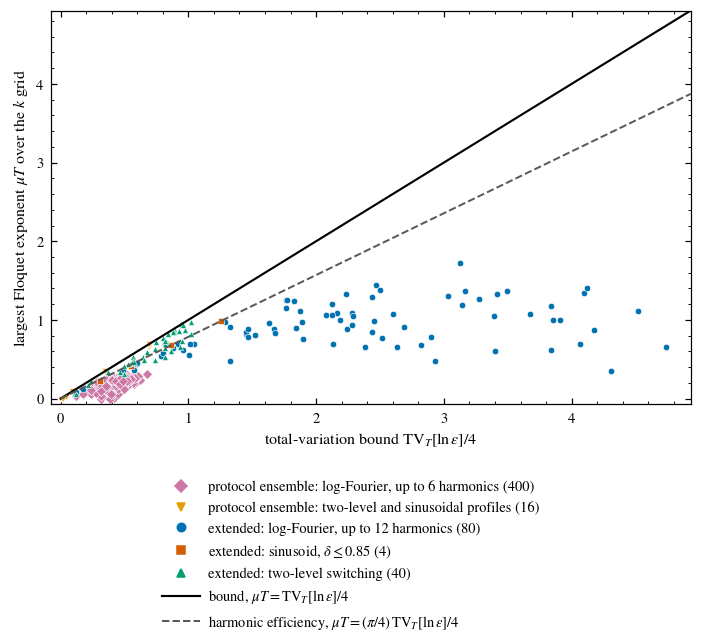

In [7]:
PI4 = math.pi / 4
fig, ax = fs.new_figure(14.5)
series = [("protocol ensemble: log-Fourier, up to 6 harmonics", rows_a, 3),
          ("protocol ensemble: two-level and sinusoidal profiles", rows_bc, 4),
          ("extended: log-Fourier, up to 12 harmonics", [r for r in rows_e4 if r["class"] == "log-Fourier"], 0),
          (r"extended: sinusoid, $\delta \leq 0.85$", [r for r in rows_e4 if r["class"] == "sinusoid"], 1),
          ("extended: two-level switching", [r for r in rows_e4 if r["class"] == "two-level"], 2)]
handles = []
for label, rows, i in series:
    st = fs.style(i)
    ax.plot([r["bound"] for r in rows], [r["max_muT"] for r in rows], st["marker"], color=st["color"],
            linestyle="none", markersize=4.2, markeredgewidth=0.4, markeredgecolor="white")
    handles.append(fs.line_handle(f"{label} ({len(rows)})", color=st["color"], marker=st["marker"],
                                  linestyle="none", markersize=5.5))
xmax = 1.04 * max(r["bound"] for r in rows_a + rows_e4)
xs = np.linspace(0.0, xmax, 200)
ax.plot(xs, xs, "-", color="black", lw=1.4)
ax.plot(xs, PI4 * xs, "--", color=fs.GREY, lw=1.3)
handles += [fs.line_handle(r"bound, $\mu T = \mathrm{TV}_T[\ln\varepsilon]/4$", color="black", lw=1.4),
            fs.line_handle(r"harmonic efficiency, $\mu T = (\pi/4)\,\mathrm{TV}_T[\ln\varepsilon]/4$",
                           color=fs.GREY, lw=1.3, linestyle="--")]
ax.set_xlim(-0.015 * xmax, xmax)
ax.set_ylim(-0.015 * xmax, xmax)
ax.set_xlabel(r"total-variation bound $\mathrm{TV}_T[\ln\varepsilon]/4$")
ax.set_ylabel(r"largest Floquet exponent $\mu T$ over the $k$ grid")
fs.legend_below(fig, handles, ncol=2)
show(fig, "f01_bound_scatter")

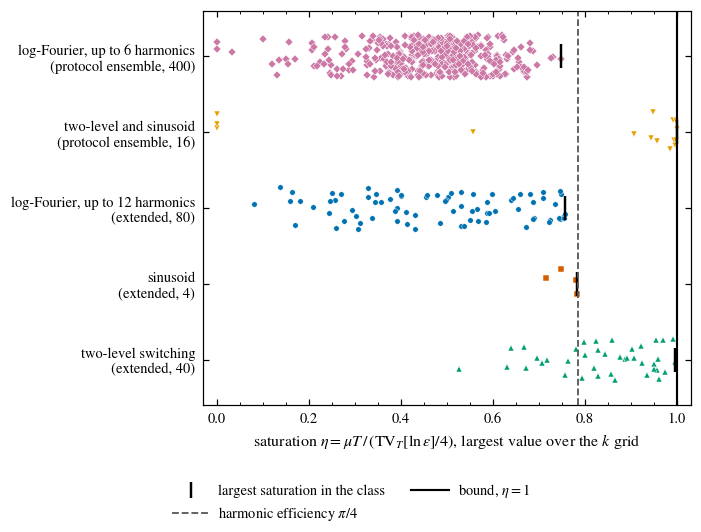

In [8]:
fig, ax = fs.new_figure(12.0)
jitter = np.random.default_rng(1)
for y, (label, rows, i) in enumerate(series[::-1]):
    sat = np.array([r["saturation"] for r in rows])
    st = fs.style(i)
    ax.plot(sat, y + jitter.uniform(-0.28, 0.28, len(sat)), st["marker"], color=st["color"], linestyle="none",
            markersize=3.6, markeredgewidth=0.3, markeredgecolor="white")
    ax.plot([sat.max()], [y], "|", color="black", markersize=16, markeredgewidth=1.6)
ax.axvline(PI4, color=fs.GREY, linestyle="--", lw=1.2)
ax.axvline(1.0, color="black", lw=1.4)
tick_labels = [f"two-level switching\n(extended, {len(series[4][1])})",
               f"sinusoid\n(extended, {len(series[3][1])})",
               f"log-Fourier, up to 12 harmonics\n(extended, {len(series[2][1])})",
               f"two-level and sinusoid\n(protocol ensemble, {len(series[1][1])})",
               f"log-Fourier, up to 6 harmonics\n(protocol ensemble, {len(series[0][1])})"]
ax.set_yticks(range(len(series)), labels=tick_labels)
ax.yaxis.set_minor_locator(NullLocator())
ax.set_ylim(-0.6, len(series) - 0.4)
ax.set_xlim(-0.03, 1.03)
ax.set_xlabel(r"saturation $\eta = \mu T\,/\,(\mathrm{TV}_T[\ln\varepsilon]/4)$, largest value over the $k$ grid")
handles = [fs.line_handle("largest saturation in the class", color="black", marker="|", linestyle="none",
                          markersize=10, markeredgewidth=1.6),
           fs.line_handle(r"harmonic efficiency $\pi/4$", color=fs.GREY, linestyle="--", lw=1.2),
           fs.line_handle(r"bound, $\eta = 1$", color="black", lw=1.4)]
fs.legend_below(fig, handles, ncol=2)
show(fig, "f02_saturation_by_class")

## 7. H3: attainability by two-level switching

### 7.1 Exact sudden switching (post hoc)

For piecewise-constant $\varepsilon$ the period map is a product of free flights, $R(\omega,\tau) = \begin{pmatrix}\cos\omega\tau & \sin(\omega\tau)/\omega\\ -\omega\sin\omega\tau & \cos\omega\tau\end{pmatrix}$, because $D$ and $\dot D$ are continuous across each jump. At the wavevector $k^\ast$ and dwell fraction of Sec. 3.3 the bound should be attained to round-off.

In [9]:
sudden = []
for r in (1.2, 2.0, 4.0):
    k_star, f2 = hill.sudden_optimum(1.0, r)
    M = hill.sudden_monodromy(1.0, r, 0.1, 0.1 + f2, k_star)
    log_rho = math.log(np.max(np.abs(np.linalg.eigvals(M))))
    sudden.append({"ratio": r, "k_star": k_star, "dwell_eps2": f2, "muT": log_rho,
                   "bound": 0.5 * math.log(r), "deficit": 1.0 - log_rho / (0.5 * math.log(r))})
    print(f"eps2/eps1 = {r}:  k* = {k_star:.6f}, dwell = {f2:.6f}, 1 - saturation = {sudden[-1]['deficit']:+.1e}")

eps2/eps1 = 1.2:  k* = 0.523861, dwell = 0.522774, 1 - saturation = -1.8e-15
eps2/eps1 = 2.0:  k* = 0.603553, dwell = 0.585786, 1 - saturation = -6.7e-16
eps2/eps1 = 4.0:  k* = 0.750000, dwell = 0.666667, 1 - saturation = +0.0e+00


### 7.2 Registered optimization

As registered, the switching phases $p_1, p_2$ (fractions of $T$) and the wavevector are optimized by differential evolution (seed 7, population 20, 60 generations) at $w/T = 0.02$, and the optimum is refined by Nelder-Mead while the ramp width is reduced to 0.01 and 0.005. Seeds 8 and 9 repeat the search at $\varepsilon_2/\varepsilon_1 = 2$ to test optimizer robustness.

In [10]:
RAMPS = (0.02, 0.01, 0.005)


def neg_saturation(x, ratio, w):
    p1, p2, k = x
    wf = hill.TwoLevelWaveform(1.0, ratio, p1 % 1.0, p2 % 1.0, w)
    b = hill.bound(wf)
    return 0.0 if b <= 0.0 else -hill.floquet_exponent(wf, k) * wf.T / b


def optimize_two_level(ratio, seed):
    de = differential_evolution(neg_saturation, bounds=[(0, 1), (0, 1), (0.3, 0.9)],
                                args=(ratio, RAMPS[0]), seed=seed, popsize=20,
                                maxiter=60, tol=1e-8, polish=False)
    x, sequence = de.x, []
    for w in RAMPS:
        res = minimize(neg_saturation, x, args=(ratio, w), method="Nelder-Mead",
                       options={"xatol": 1e-7, "fatol": 1e-10, "maxiter": 300})
        x = res.x
        sequence.append({"ramp": w, "saturation": -res.fun, "p1": x[0] % 1.0,
                         "p2": x[1] % 1.0, "k": x[2]})
    return {"ratio": ratio, "seed": seed, "de_saturation": -de.fun, "sequence": sequence}


t0 = time.perf_counter()
h3_runs = [optimize_two_level(r, 7) for r in (1.2, 2.0, 4.0)]
h3_seeds = [optimize_two_level(2.0, s) for s in (8, 9)]
print(f"optimization: {time.perf_counter() - t0:.0f} s")
for run in h3_runs:
    print(run["ratio"], [f"{s['saturation']:.5f}" for s in run["sequence"]])

optimization: 451 s
1.2 ['0.99352', '0.99837', '0.99959']
2.0 ['0.99329', '0.99832', '0.99958']
4.0 ['0.99251', '0.99812', '0.99953']


In [11]:
final = lambda run: run["sequence"][-1]
seed_spread = (max(final(r)["saturation"] for r in [h3_runs[1]] + h3_seeds)
               - min(final(r)["saturation"] for r in [h3_runs[1]] + h3_seeds))
slopes = {run["ratio"]: np.polyfit(np.log(RAMPS), np.log([1.0 - s["saturation"] for s in run["sequence"]]), 1)[0]
          for run in h3_runs}
geometry = []
for run in h3_runs:
    # The optimizer may place the high level inside or outside [p1, p2]; read the two
    # levels and the dwell at the higher one off the profile itself.
    s = final(run)
    wf = hill.TwoLevelWaveform(1.0, run["ratio"], s["p1"], s["p2"], RAMPS[-1])
    lneps = np.log(wf.eps(np.linspace(0.0, wf.T, 200001, endpoint=False)))
    lo, hi = lneps.min(), lneps.max()
    k_star, dwell_star = hill.sudden_optimum(math.exp(lo), math.exp(hi))
    geometry.append({"ratio": run["ratio"], "levels": (math.exp(lo), math.exp(hi)),
                     "k_opt": s["k"], "k_star": k_star,
                     "dwell_opt": float(np.mean(lneps > 0.5 * (lo + hi))), "dwell_star": dwell_star})
h3 = {"saturation_final": {run["ratio"]: final(run)["saturation"] for run in h3_runs},
      "saturation_by_ramp": {run["ratio"]: [s["saturation"] for s in run["sequence"]] for run in h3_runs},
      "min_final_saturation": min(final(run)["saturation"] for run in h3_runs),
      "seed_spread": seed_spread, "deficit_slope": slopes, "geometry": geometry,
      "geometry_max_rel_k": max(abs(g["k_opt"] - g["k_star"]) / g["k_star"] for g in geometry),
      "geometry_max_abs_dwell": max(abs(g["dwell_opt"] - g["dwell_star"]) for g in geometry),
      "sudden_max_abs_deficit": max(abs(s["deficit"]) for s in sudden)}
assert h3["min_final_saturation"] >= 0.99
for key, value in h3.items():
    print(f"{key:24s} {value}")

saturation_final         {1.2: np.float64(0.999593180701677), 2.0: np.float64(0.9995786251289925), 4.0: np.float64(0.9995284215889925)}
saturation_by_ramp       {1.2: [np.float64(0.9935188108488405), np.float64(0.9983741231910319), np.float64(0.999593180701677)], 2.0: [np.float64(0.9932911240649329), np.float64(0.9983161635319937), np.float64(0.9995786251289925)], 4.0: [np.float64(0.9925088556725891), np.float64(0.9981164100937171), np.float64(0.9995284215889925)]}
min_final_saturation     0.9995284215889925
seed_spread              1.297850715786808e-13
deficit_slope            {1.2: np.float64(1.9968992580099998), 2.0: np.float64(1.996447439496963), 4.0: np.float64(1.99480826992167)}
geometry                 [{'ratio': 1.2, 'levels': (1.0, 1.2), 'k_opt': np.float64(0.5238605609143863), 'k_star': 0.523861278752583, 'dwell_opt': 0.5223123884380578, 'dwell_star': 0.5227744249483388}, {'ratio': 2.0, 'levels': (1.0, 2.0), 'k_opt': np.float64(0.6035411353031039), 'k_star': 0.60355339059327

### 7.3 Approach to the sudden limit

The deficit $1 - \text{saturation}$ falls by close to a factor of four each time the ramp width halves, i.e. it scales as $(w/T)^2$, and the optimizer converges to the geometry of the exact sudden solution. Figure 3 shows the approach to the bound on logarithmic axes.

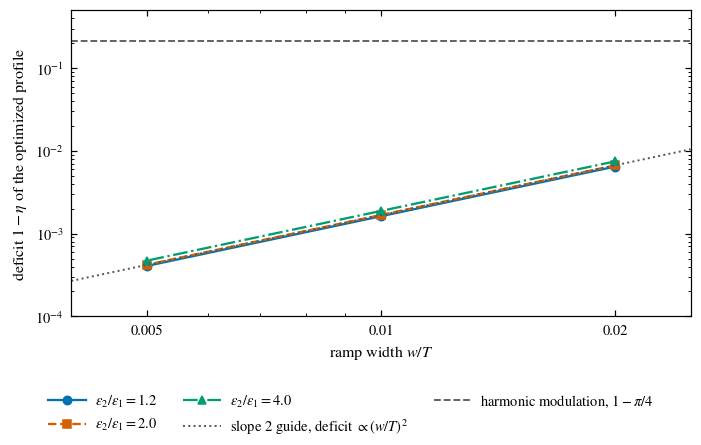

In [12]:
fig, ax = fs.new_figure(10.0)
handles = []
for i, run in enumerate(h3_runs):
    st = fs.style(i)
    ax.plot(RAMPS, [1.0 - s["saturation"] for s in run["sequence"]], color=st["color"],
            marker=st["marker"], linestyle=st["linestyle"], markersize=5.5)
    handles.append(fs.line_handle(rf"$\varepsilon_2/\varepsilon_1 = {run['ratio']}$", color=st["color"],
                                  marker=st["marker"], linestyle=st["linestyle"], markersize=5.5))
guide = h3_runs[1]["sequence"][0]
ww = np.array([0.004, 0.025])
ax.plot(ww, (1.0 - guide["saturation"]) * (ww / guide["ramp"]) ** 2, color=fs.GREY, linestyle=":", lw=1.3)
ax.axhline(1.0 - PI4, color=fs.GREY, linestyle="--", lw=1.2)
handles += [fs.line_handle(r"slope 2 guide, deficit $\propto (w/T)^2$", color=fs.GREY, linestyle=":", lw=1.3),
            fs.line_handle(r"harmonic modulation, $1 - \pi/4$", color=fs.GREY, linestyle="--", lw=1.2)]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([0.005, 0.01, 0.02], labels=["0.005", "0.01", "0.02"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(0.004, 0.025)
ax.set_ylim(1e-4, 0.5)
ax.set_xlabel(r"ramp width $w/T$")
ax.set_ylabel(r"deficit $1 - \eta$ of the optimized profile")
fs.legend_below(fig, handles, ncol=3)
show(fig, "f03_two_level_deficit")

### 7.4 Uncertainty budget for sharp ramps

The profile carrying the saturation result has ramps that occupy half a percent of the period. Without a step cap the adaptive controller can take steps longer than a ramp, in which case the error is set by step placement rather than by the tolerances. We therefore measure the two components separately at $w/T = 0.005$, on the three optimized profiles and on the three profiles with the exact sudden-switching geometry: the step component from a sequence of step caps, with $T/4000$ as reference, and the tolerance component from the tolerance change $10^{-9} \to 10^{-13}$ under the production cap.

In [13]:
sharp = []
for run in h3_runs:
    s = final(run)
    sharp.append((f"optimized, ratio {run['ratio']}", hill.TwoLevelWaveform(1.0, run["ratio"], s["p1"], s["p2"], 0.005), s["k"]))
for r in (1.2, 2.0, 4.0):
    k_star, f2 = hill.sudden_optimum(1.0, r)
    sharp.append((f"sudden geometry, ratio {r}", hill.TwoLevelWaveform(1.0, r, 0.1, 0.1 + f2, 0.005), k_star))

CAPS = {"none": np.inf, "T/20": 2 * math.pi / 20, "T/50": 2 * math.pi / 50, "T/200": 2 * math.pi / 200,
        "production, T/400": 2 * math.pi / 400, "T/1000": 2 * math.pi / 1000, "T/4000": 2 * math.pi / 4000}
budget_rows = []
for name, wf, k in sharp:
    assert math.isclose(wf.max_step(), CAPS["production, T/400"])
    mu = {cap: hill.floquet_exponent(wf, k, max_step=c) * wf.T for cap, c in CAPS.items()}
    ref = mu["T/4000"]
    tol = max(abs(hill.floquet_exponent(wf, kk, rtol=1e-9, atol=1e-11)
                  - hill.floquet_exponent(wf, kk, rtol=1e-13, atol=1e-15)) * wf.T for kk in (0.45, k, 0.9))
    budget_rows.append({"profile": name, "muT_by_cap": mu, "step_uncapped": abs(mu["none"] - ref),
                        "step_production": abs(mu["production, T/400"] - ref), "tolerance": tol,
                        "saturation_shift_uncapped": (mu["none"] - ref) / hill.bound(wf)})
budget = {"rows": budget_rows,
          "step_component_uncapped": max(r["step_uncapped"] for r in budget_rows),
          "step_component_production": max(r["step_production"] for r in budget_rows),
          "tolerance_component": max(r["tolerance"] for r in budget_rows),
          "saturation_shift_uncapped": max(abs(r["saturation_shift_uncapped"]) for r in budget_rows)}
save_json("h3_two_level.json", {"sudden": sudden, "runs": h3_runs, "seed_runs": h3_seeds, **h3,
                                 "uncertainty": budget})
summary["H3"] = {**h3, "sudden": sudden, "uncertainty": {k: v for k, v in budget.items() if k != "rows"}}
for r in budget_rows:
    print(f"{r['profile']:28s} uncapped {r['step_uncapped']:.1e}  production cap {r['step_production']:.1e}  "
          f"tolerance {r['tolerance']:.1e}")
print(f"largest step component without a cap {budget['step_component_uncapped']:.1e} "
      f"(saturation shift {budget['saturation_shift_uncapped']:.1e}); with the production cap "
      f"{budget['step_component_production']:.1e}; tolerance component {budget['tolerance_component']:.1e}")

optimized, ratio 1.2         uncapped 3.7e-12  production cap 9.7e-15  tolerance 2.2e-15
optimized, ratio 2.0         uncapped 3.0e-13  production cap 1.7e-14  tolerance 1.8e-13
optimized, ratio 4.0         uncapped 1.7e-13  production cap 2.8e-15  tolerance 3.0e-11
sudden geometry, ratio 1.2   uncapped 2.0e-13  production cap 1.3e-14  tolerance 3.0e-15
sudden geometry, ratio 2.0   uncapped 1.4e-13  production cap 3.5e-14  tolerance 9.3e-14
sudden geometry, ratio 4.0   uncapped 2.0e-13  production cap 1.6e-14  tolerance 3.9e-11
largest step component without a cap 3.7e-12 (saturation shift 4.1e-11); with the production cap 3.5e-14; tolerance component 3.9e-11


## 8. H2: efficiency of harmonic modulation

### 8.1 Registered test

At each registered depth the exponent is maximized over a 25-point grid $k \in [0.5 - 3\delta^2 - 0.002,\ 0.5 + 0.002]$ around the tongue center, as fixed in the protocol.

### 8.2 Depth sweep (post hoc)

The leading-order argument of Sec. 3.4 says nothing about large depths. Here the tongue maximum is located by three levels of nested 121-point grids followed by a bounded Brent search, for depths up to $\delta = 0.6$. The comparison with Sec. 8.1 also shows how much of the small shortfall of the registered values comes from the 25-point grid.

In [14]:
def tongue_maximum(wf, lo, hi):
    # Three levels of nested 121-point grids, then a bounded Brent search.
    for _ in range(3):
        kk = np.linspace(lo, hi, 121)
        mus = np.array([hill.floquet_exponent(wf, k) for k in kk])
        k_best = kk[int(np.argmax(mus))]
        span = (hi - lo) / 20.0
        lo, hi = k_best - span, k_best + span
    res = minimize_scalar(lambda k: -hill.floquet_exponent(wf, k), bounds=(lo, hi),
                          method="bounded", options={"xatol": 1e-12})
    return max(mus.max(), -res.fun) * wf.T


h2_registered, h2_sweep = [], []
for d in (0.005, 0.01, 0.02, 0.04):
    wf = hill.SinusoidWaveform(delta=d)
    kk = np.linspace(0.5 - 3 * d * d - 0.002, 0.5 + 0.002, 25)
    muT = max(hill.floquet_exponent(wf, k) for k in kk) * wf.T
    h2_registered.append({"delta": d, "muT": muT, "bound": hill.bound(wf),
                          "efficiency_over_pi4": muT / hill.bound(wf) / PI4})
for d in (0.005, 0.01, 0.02, 0.04, 0.08, 0.15, 0.25, 0.40, 0.60):
    wf = hill.SinusoidWaveform(delta=d)
    lo, hi = max(0.05, 0.5 - max(0.01, 1.2 * d)), min(0.75, 0.5 + max(0.01, 1.2 * d))
    muT = tongue_maximum(wf, lo, hi)
    h2_sweep.append({"delta": d, "muT": muT, "bound": hill.bound(wf),
                     "efficiency_over_pi4": muT / hill.bound(wf) / PI4})
h2 = {"registered": h2_registered, "sweep": h2_sweep,
      "registered_max_deviation": max(abs(x["efficiency_over_pi4"] - 1) for x in h2_registered
                                      if x["delta"] <= 0.02),
      "registered_all_deviation": max(abs(x["efficiency_over_pi4"] - 1) for x in h2_registered),
      "sweep_max_deviation": max(abs(x["efficiency_over_pi4"] - 1) for x in h2_sweep),
      "sweep_max_delta": max(x["delta"] for x in h2_sweep)}
save_json("h2_harmonic.json", h2)
summary["H2"] = h2
assert h2["registered_max_deviation"] < 0.02
for x, y in zip(h2_registered, h2_sweep):
    print(f"delta = {x['delta']:.3f}: registered grid {x['efficiency_over_pi4']:.5f}, refined {y['efficiency_over_pi4']:.5f}")
for y in h2_sweep[4:]:
    print(f"delta = {y['delta']:.3f}: refined {y['efficiency_over_pi4']:.5f}")
print(f"largest deviation from pi/4 up to delta = {h2['sweep_max_delta']}: {h2['sweep_max_deviation']:.2e}")

delta = 0.005: registered grid 0.99840, refined 1.00000
delta = 0.010: registered grid 0.99954, refined 1.00000
delta = 0.020: registered grid 0.99943, refined 1.00000
delta = 0.040: registered grid 0.99992, refined 1.00000
delta = 0.080: refined 0.99999
delta = 0.150: refined 0.99997
delta = 0.250: refined 0.99992
delta = 0.400: refined 0.99977
delta = 0.600: refined 0.99942
largest deviation from pi/4 up to delta = 0.6: 5.81e-04


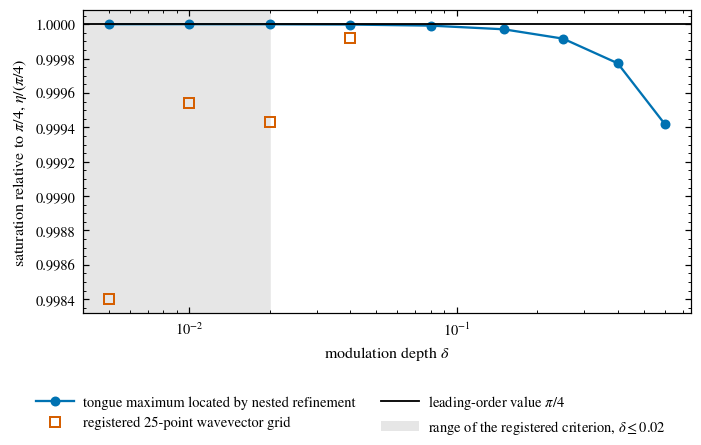

In [15]:
fig, ax = fs.new_figure(10.0)
st0, st1 = fs.style(0), fs.style(1)
ax.axvspan(0.004, 0.02, color="0.9", zorder=0)
ax.plot([x["delta"] for x in h2_sweep], [x["efficiency_over_pi4"] for x in h2_sweep], color=st0["color"],
        marker=st0["marker"], linestyle="-", markersize=5.5)
ax.plot([x["delta"] for x in h2_registered], [x["efficiency_over_pi4"] for x in h2_registered],
        color=st1["color"], marker=st1["marker"], linestyle="none", markersize=6.5, markerfacecolor="none",
        markeredgewidth=1.3)
ax.axhline(1.0, color="black", lw=1.2)
handles = [fs.line_handle("tongue maximum located by nested refinement", color=st0["color"],
                          marker=st0["marker"], markersize=5.5),
           fs.line_handle("registered 25-point wavevector grid", color=st1["color"], marker=st1["marker"],
                          linestyle="none", markersize=6.5, markerfacecolor="none", markeredgewidth=1.3),
           fs.line_handle(r"leading-order value $\pi/4$", color="black", lw=1.2),
           Patch(facecolor="0.9", edgecolor="none", label=r"range of the registered criterion, $\delta \leq 0.02$")]
ax.set_xscale("log")
ax.set_xlim(0.004, 0.75)
ax.set_xlabel(r"modulation depth $\delta$")
ax.set_ylabel(r"saturation relative to $\pi/4$, $\eta/(\pi/4)$")
fs.legend_below(fig, handles, ncol=2)
show(fig, "f04_harmonic_efficiency")

# Part II. Lossy dispersive media

## 9. Theory II: lossy Lorentz medium

### 9.1 Model

The medium has one Lorentz resonance, $\ddot P + \gamma\dot P + \omega_r^2(t)P = \omega_p^2(t)E$, with $D = E + P$ (unit background permittivity). With $Q = \dot P$ the state $u = (D, H, P, Q)$ of one wavevector evolves as

$$\dot D = -ikH,\qquad \dot H = -ik(D - P),\qquad \dot P = Q,\qquad \dot Q = -\gamma Q - \omega_r^2(t)P + \omega_p^2(t)(D - P).$$

We modulate one channel harmonically: the squared resonance frequency, $\omega_r^2(t) = \omega_{r0}^2(1 + m\cos\Omega t)$ (*resonance channel*), or the squared plasma frequency, $\omega_p^2(t) = \omega_{p0}^2(1 + m\cos\Omega t)$ (*plasma channel*). The first corresponds to modulating the restoring force of the oscillators, the second to modulating their density at fixed damping. The reference medium has $\omega_{r0} = 1$ and $\omega_{p0} = 0.8$. Without loss and modulation the dispersion relation $k^2 = \omega^2\varepsilon(\omega)$, $\varepsilon(\omega) = 1 + \omega_{p0}^2/(\omega_{r0}^2 - \omega^2)$, has two branches,

$$\omega_\pm^2 = \tfrac12\Bigl[\omega_{r0}^2 + \omega_{p0}^2 + k^2 \pm \sqrt{(\omega_{r0}^2 + \omega_{p0}^2 + k^2)^2 - 4k^2\omega_{r0}^2}\Bigr],$$

with $\omega_- < \omega_{r0}$ and $\omega_+^2 \ge \omega_{r0}^2 + \omega_{p0}^2$.

### 9.2 Energy and its balance

The quadratic form

$$W = \tfrac12|E|^2 + \tfrac12|H|^2 + \frac{|Q|^2 + \omega_r^2|P|^2}{2\omega_p^2}$$

is conserved when $\gamma = 0$ and the parameters are static. Its last term is the matter energy $W_m$. With time-dependent parameters the exact balance is

$$\frac{dW}{dt} = -\frac{\gamma}{\omega_p^2}|Q|^2 + \frac{|P|^2}{2\omega_p^2}\frac{d\omega_r^2}{dt} - \frac{d\ln\omega_p^2}{dt}\,W_m ,$$

which the next cell verifies symbolically. Writing $f_{\rm pot} = \omega_r^2|P|^2/(2\omega_p^2 W)$, $f_{\rm kin} = |Q|^2/(2\omega_p^2 W)$ and $f_m = f_{\rm pot} + f_{\rm kin}$ for the potential, kinetic and total matter fractions and bounding each modulation term by its modulus gives the growth inequality

$$\frac{d\ln W}{dt} \le f_{\rm pot}\Bigl|\frac{d\ln\omega_r^2}{dt}\Bigr| + f_m\Bigl|\frac{d\ln\omega_p^2}{dt}\Bigr| - 2\gamma f_{\rm kin},$$

the subject of H4b. Each channel pumps the medium only through its matter fraction, while damping drains the kinetic part.

In [16]:
t = sp.Symbol("t", real=True)
k_s, g_s = sp.symbols("k gamma", positive=True)
D, Hi, P, Q = (sp.Function(name)(t) for name in ("D", "Hi", "P", "Q"))
wr2_t, wp2_t = sp.Function("omega_r2")(t), sp.Function("omega_p2")(t)
E_f = D - P
# Real form of the equations with Hi = i H: D' = -k Hi, Hi' = k E
eom = {D.diff(t): -k_s * Hi, Hi.diff(t): k_s * E_f, P.diff(t): Q,
       Q.diff(t): -g_s * Q - wr2_t * P + wp2_t * E_f}
W_m = (Q**2 + wr2_t * P**2) / (2 * wp2_t)
W_s = sp.Rational(1, 2) * (E_f**2 + Hi**2) + W_m
balance = (-g_s * Q**2 / wp2_t + wr2_t.diff(t) * P**2 / (2 * wp2_t) - wp2_t.diff(t) / wp2_t * W_m)
residual = sp.simplify(sp.expand(W_s.diff(t).subs(eom) - balance))
assert residual == 0
print("energy balance verified symbolically: residual =", residual)

energy balance verified symbolically: residual = 0


### 9.3 Two-mode reduction

Let $G$ be the matrix of $2W$, so that $u^\dagger G u = 2W$, and let $A_0$ be the static lossless generator. Then $GA_0$ is anti-Hermitian, $W$ is conserved, and eigenvectors with different frequencies are $G$-orthogonal. On branch $j$ the eigenvectors of $A_0$ with eigenvalues $\mp i\omega_j$ are

$$v_\pm = \bigl(1,\ \pm\omega_j/k,\ p,\ \mp i\omega_j p\bigr), \qquad e = \omega_j^2/k^2,\quad p = 1 - e,$$

where $e = 1/\varepsilon(\omega_j)$ is the inverse permittivity on shell and $p$ the polarization amplitude per unit displacement; their $G$-norm is $N = e^2 + e + (\omega_{r0}^2 + \omega_j^2)p^2/\omega_{p0}^2$. Near $\Omega = 2\omega_j$ we write $u \approx a(t)v_+e^{-i\omega_j t} + b(t)v_-e^{i\omega_j t}$, project the modulation and the loss onto the two modes with $G$, and average over the fast phase. This gives

$$\dot a = -\gamma K a + c_{+-}b, \qquad \dot b = c_{-+}a - \gamma K b, \qquad c_{\pm\mp} = \frac{m}{2}\frac{v_\pm^\dagger G A_1 v_\mp}{N},$$

with $A_1$ the modulated part of the generator. The growing solution has the net exponent

$$\mu_{\rm net} = |F|\,\frac{m\,\omega_j}{4} - \gamma K, \qquad F^{(\omega_r^2)} = \frac{2\omega_{r0}^2p^2}{\omega_{p0}^2N},\quad F^{(\omega_p^2)} = \frac{2ep}{N},\quad K = \frac{\omega_j^2p^2}{\omega_{p0}^2N}.$$

On the upper branch $e > 1$, so $p < 0$ and $F^{(\omega_p^2)} < 0$; the rate depends on $\sqrt{c_{+-}c_{-+}}$, which is why the modulus $|F|$ appears.

### 9.4 Exact reduction: ceiling and thresholds

With $A = \omega_{r0}^2 - \omega_j^2$ and $B = \omega_{p0}^2$, the on-shell relations $e = A/(A+B)$ and $p = B/(A+B)$ reduce the factors to

$$N = \frac{2\Delta}{(A+B)^2},\qquad F^{(\omega_r^2)} = \frac{B\omega_{r0}^2}{\Delta},\qquad F^{(\omega_p^2)} = \frac{AB}{\Delta},\qquad K = \frac{B\omega_j^2}{2\Delta},\qquad \Delta = A^2 + \omega_{r0}^2 B .$$

The two branch frequencies are the roots of $\omega^4 - (\omega_{r0}^2 + \omega_{p0}^2 + k^2)\,\omega^2 + k^2\omega_{r0}^2 = 0$, so Vieta's relations give $A_+A_- = -\omega_{r0}^2\omega_{p0}^2$, and the factors take a form in which their bounds are evident:

$$F^{(\omega_r^2)}_- = \frac{\omega_+^2 - \omega_{r0}^2}{\omega_+^2 - \omega_-^2},\qquad F^{(\omega_r^2)}_+ = \frac{\omega_{r0}^2 - \omega_-^2}{\omega_+^2 - \omega_-^2},\qquad \bigl|F^{(\omega_p^2)}_\pm\bigr| = \frac{\omega_{p0}^2}{\omega_+^2 - \omega_-^2},\qquad K = \frac{\omega_j^2}{2\omega_{r0}^2}\,F^{(\omega_r^2)} .$$

The resonance-channel factors are lever-rule fractions of the polariton splitting, $F_-^{(\omega_r^2)} + F_+^{(\omega_r^2)} = 1$, and lie strictly between 0 and 1 because $\omega_-^2 < \omega_{r0}^2 < \omega_+^2$. The plasma-channel factor has the same modulus on both branches, and $(\omega_+^2 - \omega_-^2)^2 - \omega_{p0}^4 = (\omega_{r0}^2 - k^2)^2 + 2\omega_{p0}^2(\omega_{r0}^2 + k^2) > 0$. Hence $|F| < 1$ in both channels, on both branches and in every medium: the gain never exceeds the bare parametric value $m\omega_j/4$. The bound is sharp only for the resonance channel, where $F_-^{(\omega_r^2)} \to 1$ as $k \to \infty$ and the lower branch approaches $\omega_{r0}$. The plasma channel stays away from it: its largest participation is $\omega_{p0}/(2\omega_{r0})$, reached at $k^2 = \omega_{r0}^2 - \omega_{p0}^2$, when $\omega_{p0} \le \omega_{r0}$, and $\omega_{p0}^2/(\omega_{r0}^2 + \omega_{p0}^2)$, approached as $k \to 0$, otherwise.

Setting $\mu_{\rm net} = 0$ gives the thresholds

$$m_c^{(\omega_r^2)} = \frac{2\gamma\omega_j}{\omega_{r0}^2}, \qquad m_c^{(\omega_p^2)} = \frac{2\gamma\omega_j}{|\omega_{r0}^2 - \omega_j^2|}.$$

The first is independent of the detuning from resonance, because the loss factor $K$ is proportional to the same participation $F^{(\omega_r^2)}$ that sets the gain. The plasma channel loses this proportionality, $F^{(\omega_r^2)}/F^{(\omega_p^2)} = \omega_{r0}^2/A$: its coupling collapses at resonance while its loss does not, and its threshold diverges there. The next two cells check the reduction and the branch forms with SymPy.

In [17]:
w_s, a0, B_s, k_s2, m_s, gam = sp.symbols("omega a0 B k m gamma", positive=True)   # a0 = omega_r0^2, B = omega_p0^2
A_s = a0 - w_s**2
e_s = A_s / (A_s + B_s)
p_s = 1 - e_s
N_eig = e_s**2 + e_s + (a0 + w_s**2) * p_s**2 / B_s
Delta_s = A_s**2 + a0 * B_s
identities = {
    "N": N_eig - 2 * Delta_s / (A_s + B_s)**2,
    "F_wr2": 2 * a0 * p_s**2 / (B_s * N_eig) - B_s * a0 / Delta_s,
    "F_wp2": 2 * e_s * p_s / N_eig - A_s * B_s / Delta_s,
    "K": w_s**2 * p_s**2 / (B_s * N_eig) - B_s * w_s**2 / (2 * Delta_s),
}
for name, expr in identities.items():
    assert sp.simplify(expr) == 0, name
    print(f"{name:6s} reduces exactly")
K_red = B_s * w_s**2 / (2 * Delta_s)
for name, F in (("resonance channel", B_s * a0 / Delta_s), ("plasma channel", A_s * B_s / Delta_s)):
    m_c = sp.solve(sp.Eq(F * m_s * w_s / 4, gam * K_red), m_s)[0]
    print(f"threshold, {name}: m_c =", sp.simplify(m_c))

N      reduces exactly
F_wr2  reduces exactly
F_wp2  reduces exactly
K      reduces exactly
threshold, resonance channel: m_c = 2*gamma*omega/a0


threshold, plasma channel: m_c = 2*gamma*omega/(a0 - omega**2)


In [18]:
# Branch forms: x = omega^2 runs over the two roots x_- < x_+ of the dispersion quadratic.
s_sum, s_prod = a0 + B_s + k_s2**2, k_s2**2 * a0
x_m = (s_sum - sp.sqrt(s_sum**2 - 4 * s_prod)) / 2
x_p = (s_sum + sp.sqrt(s_sum**2 - 4 * s_prod)) / 2
F_r = lambda x: B_s * a0 / ((a0 - x)**2 + a0 * B_s)
F_p = lambda x: (a0 - x) * B_s / ((a0 - x)**2 + a0 * B_s)
K_x = lambda x: B_s * x / (2 * ((a0 - x)**2 + a0 * B_s))
branch_forms = {
    "F_wr2 lower = (x+ - a0)/(x+ - x-)": F_r(x_m) - (x_p - a0) / (x_p - x_m),
    "F_wr2 upper = (a0 - x-)/(x+ - x-)": F_r(x_p) - (a0 - x_m) / (x_p - x_m),
    "F_wp2 lower = B/(x+ - x-)": F_p(x_m) - B_s / (x_p - x_m),
    "F_wp2 upper = -B/(x+ - x-)": F_p(x_p) + B_s / (x_p - x_m),
    "K = x F_wr2/(2 a0)": K_x(w_s**2) - w_s**2 * F_r(w_s**2) / (2 * a0),
    "(x+ - x-)^2 - B^2 = (a0 - k^2)^2 + 2B(a0 + k^2)":
        (x_p - x_m)**2 - B_s**2 - ((a0 - k_s2**2)**2 + 2 * B_s * (a0 + k_s2**2)),
}
for name, expr in branch_forms.items():
    assert sp.simplify(sp.radsimp(sp.together(expr))) == 0, name
    print(f"{name:48s} holds identically")

F_wr2 lower = (x+ - a0)/(x+ - x-)                holds identically


F_wr2 upper = (a0 - x-)/(x+ - x-)                holds identically


F_wp2 lower = B/(x+ - x-)                        holds identically


F_wp2 upper = -B/(x+ - x-)                       holds identically
K = x F_wr2/(2 a0)                               holds identically
(x+ - x-)^2 - B^2 = (a0 - k^2)^2 + 2B(a0 + k^2)  holds identically


### 9.5 Interbranch crossings and the four-mode theory (post hoc)

The two-mode reduction assumes that no other mode is resonant with the drive. On the lower branch with $\Omega = 2\omega_-$, the beat between $+\omega_-$ and $+\omega_+$ is resonant when $\omega_+ - \omega_- = \Omega$, i.e. $\omega_+ = 3\omega_-$. Using $\omega_+\omega_- = k\omega_{r0}$ and $\omega_+^2 + \omega_-^2 = \omega_{r0}^2 + \omega_{p0}^2 + k^2$, this happens where

$$k^2 - \tfrac{10}{3}\,\omega_{r0}\,k + \omega_{r0}^2 + \omega_{p0}^2 = 0,$$

which for the reference medium gives $k^\ast = 0.600$ and $k^\ast = 2.733$ exactly. These values are specific to $\omega_{r0} = 1$, $\omega_{p0} = 0.8$. Near $k^\ast$ the modes $\{+\omega_-, -\omega_-, +\omega_+, -\omega_+\}$ form a secular set. Projecting with $G$ as before gives the $4\times4$ matrix

$$S = \begin{pmatrix} -\kappa_- & c_{ab} & c_{ac} & 0\\ c_{ba} & -\kappa_- & 0 & c_{bd}\\ c_{ca} & 0 & -\kappa_+ - i\delta_\times & 0\\ 0 & c_{db} & 0 & -\kappa_+ + i\delta_\times\end{pmatrix}, \qquad \kappa_\pm = \gamma K_\pm,\quad \delta_\times = \omega_+ - 3\omega_-,$$

written in a frame that rotates at $\omega_-$ for the lower modes and at $3\omega_-$ for the upper ones. The real parts of its four eigenvalues approximate all four Floquet exponents of the medium; the parametric pair is carried by the two eigenvectors with the largest weight on the lower-branch modes. With the eigenvectors of Sec. 9.3 and $\nu_l$ the signed frequency of mode $l$, the couplings are built from $v_l^\dagger G A_1 v_j = -i\nu_l p_l p_j\,\omega_{r0}^2/\omega_{p0}^2$ in the resonance channel and $v_l^\dagger G A_1 v_j = i\nu_l p_l e_j$ in the plasma channel. For the beat between $+\omega_-$ and $+\omega_+$ the product $c_{ac}c_{ca}$ is therefore negative in the resonance channel, as for frequency conversion between two positive-frequency modes: the beat repels the levels and mixes the pair with the other branch, whose loss factor can differ strongly. In the plasma channel the product is positive, because the polarization amplitude $p$ changes sign between the branches, and the beat itself supplies gain. Far from $k^\ast$ the upper modes detune and $S$ reduces to the two-mode result. On the upper branch with $\Omega = 2\omega_+$ the corresponding conditions, $\omega_+ \pm \omega_- = 2\omega_+$, have no solution, so no first-order crossing exists there. This theory was derived after the registered scan had revealed the failures near $k^\ast$ and is labeled post hoc throughout.

### 9.6 Algorithms

* **Monodromy.** The four columns of the identity are integrated together as one 16-component complex system with DOP853 (tolerances as in Part I). A modulation period contains about two field periods, so no step cap is needed.
* **Tongue pair.** At the first tongue the parametrically coupled multipliers sit near $-1$. The pair whose arguments are closest to $\pm\pi$ is selected; its larger exponent is $\mu_{\rm pair}$ and the difference of its two exponents is the *split*, which vanishes outside the gap.
* **Gap detector.** At fixed $\Omega$ a wavevector is in the gap when the split exceeds $10^{-9}$. A width is the number of in-gap grid points times the grid spacing; its uncertainty is one spacing.
* **Audit.** Liouville's formula gives $\det M = e^{-\gamma T}$ because the trace of the generator is $-\gamma$; every production monodromy is checked against it.

## 10. Validation of the Lorentz solver

B5 compares the multipliers of the static medium with $e^{sT}$, where $s$ runs over the roots of the dispersion quartic $(s^2 + k^2)(s^2 + \gamma s + \omega_{r0}^2 + \omega_{p0}^2) - k^2\omega_{p0}^2 = 0$. B6 switches the oscillator off ($\omega_p^2 = 10^{-14}$) and modulates the background permittivity instead, which must reproduce the Hill solver. A reference integrator that propagates the four columns separately cross-checks the stacked production integrator.

In [19]:
validation_lorentz = {}
b5 = []
for gamma in (0.0, 0.02):
    med = L.LorentzMedium(k=1.3, gamma=gamma, Om=2.0)
    ev = np.linalg.eigvals(med.monodromy())
    b5.append(L.multiset_distance(ev, np.exp(L.static_roots(1.3, gamma) * med.T)))
validation_lorentz["B5_lossless"], validation_lorentz["B5_lossy"] = b5

wf = hill.SinusoidWaveform(delta=0.02)
med = L.LorentzMedium(k=0.5, gamma=0.0, Om=1.0, wp2=lambda t: 1e-14 + 0.0 * np.asarray(t), epsb=wf.eps)
validation_lorentz["B6_abs_error"] = abs(med.max_exponent() - hill.floquet_exponent(wf, 0.5))

cross = []
for k, gamma, m, channel in ((0.8, 0.01, 0.05, "wp2"), (1.5, 0.003, 0.02, "wr2"), (2.5, 0.03, 0.1, "wp2")):
    Om = 2.0 * L.polariton_omega(k)
    M, T = L.monodromy(k, gamma, m, Om, channel)
    mod = lambda t, Om=Om, m=m: 1.0 + m * np.cos(Om * np.asarray(t))
    ref = L.LorentzMedium(k=k, gamma=gamma, Om=Om,
                          wr2=(lambda t: L.WR2 * mod(t)) if channel == "wr2" else None,
                          wp2=(lambda t: L.WP2 * mod(t)) if channel == "wp2" else None)
    cross.append(abs(np.max(np.log(np.abs(np.linalg.eigvals(M)))) / T - ref.max_exponent()))
validation_lorentz["stacked_vs_reference"] = max(cross)
assert b5[0] < 1e-9 and b5[1] < 1e-8 and validation_lorentz["B6_abs_error"] < 1e-8
assert validation_lorentz["stacked_vs_reference"] < 1e-12
save_json("validation_lorentz.json", validation_lorentz)
summary["benchmarks_lorentz"] = validation_lorentz
for key, value in validation_lorentz.items():
    print(f"{key:24s} {value:.2e}")

B5_lossless              2.92e-12
B5_lossy                 2.89e-12
B6_abs_error             2.02e-12
stacked_vs_reference     1.54e-14


## 11. H4a: net rates on the lower polariton branch

The registered scan E2 covers 80 wavevectors $k \in [0.25, 3]$ for both channels, four loss rates and four modulation indices (32 combinations). The drive tracks the tongue center, $\Omega = 2\omega_-(k)$, which makes the two-mode formula a pointwise prediction at every grid point. H4a concerns the confirmatory subset $m \le 0.05$, $\gamma \le 0.03$ (24 combinations). Relative errors are meaningless where the predicted rate passes through zero, so points with $|\mu_{\rm pred}| < 10^{-4}$ are assessed by their absolute error instead.

In [20]:
K_E2 = np.linspace(0.25, 3.0, 80)
GAMMAS, MODS = (1e-3, 3e-3, 1e-2, 3e-2), (0.01, 0.02, 0.05, 0.1)
COLS = ("k", "omega", "F", "K", "mu_pred", "mu_pair", "split", "mu_max", "liouville_error")
t0 = time.perf_counter()
scan = []
for channel in ("wr2", "wp2"):
    for gamma in GAMMAS:
        for m in MODS:
            rows = []
            for k in K_E2:
                pred, w, F, K = L.net_rate(k, m, gamma, channel)
                M, T = L.monodromy(k, gamma, m, 2.0 * w, channel)
                rows.append((k, w, F, K, pred, *L.tongue_pair(M, T), L.liouville_error(M, gamma, T)))
            a = np.array(rows)
            scan.append({"channel": channel, "gamma": gamma, "m": m,
                         **{name: a[:, i] for i, name in enumerate(COLS)}})
print(f"{len(scan)} combinations x {len(K_E2)} wavevectors, {time.perf_counter() - t0:.0f} s")
save_json("lower_branch_scan.json", {"k_grid": K_E2, "combinations": scan})

32 combinations x 80 wavevectors, 40 s


In [21]:
K_STAR = L.interbranch_crossings()
n_all = n_away = fail_all = fail_away = 0
worst_all, rel_away, near_abs, fail_dist = 0.0, [], [], []
for c in scan:
    if c["m"] > 0.05 or c["gamma"] > 0.03:
        continue
    big = np.abs(c["mu_pred"]) >= 1e-4
    rel = np.abs(c["mu_pair"] - c["mu_pred"]) / np.where(big, np.abs(c["mu_pred"]), 1.0)
    dist = np.min([np.abs(c["k"] - ks) for ks in K_STAR], axis=0)
    away = dist > 0.05
    n_all += big.sum()
    n_away += (big & away).sum()
    fail_all += (big & (rel > 0.10)).sum()
    fail_away += (big & away & (rel > 0.10)).sum()
    worst_all = max(worst_all, rel[big].max())
    rel_away += list(rel[big & away])
    near_abs += list(np.abs(c["mu_pair"] - c["mu_pred"])[~big])
    fail_dist += list(dist[big & (rel > 0.10)])
rel_away = np.array(rel_away)
h4a = {"crossings": K_STAR, "n_points": n_all, "n_fail_registered": fail_all,
       "worst_rel_registered": worst_all, "max_fail_distance_to_crossing": max(fail_dist, default=0.0),
       "n_points_away": n_away, "n_fail_away": fail_away, "median_rel_away": np.median(rel_away),
       "p95_rel_away": np.percentile(rel_away, 95), "worst_rel_away": rel_away.max(),
       "n_near_threshold": len(near_abs), "max_abs_near_threshold": max(near_abs, default=0.0),
       "max_liouville_error": max(c["liouville_error"].max() for c in scan)}
summary["H4a"] = h4a
for key, value in h4a.items():
    print(f"{key:30s} {value}")

crossings                      [0.5999999999999999, 2.7333333333333334]
n_points                       1842
n_fail_registered              19
worst_rel_registered           1.5909926636373295
max_fail_distance_to_crossing  0.011814345991561392
n_points_away                  1707
n_fail_away                    0
median_rel_away                6.242218837483696e-05
p95_rel_away                   0.0015365498645379097
worst_rel_away                 0.027138320450664527
n_near_threshold               78
max_abs_near_threshold         0.00014244076162206403
max_liouville_error            3.1280533718813786e-12


**Outcome.** H4a fails as registered: a small set of points deviates by more than 10%. Every failing point lies within 0.05 of one of the two interbranch crossings $k^\ast$ of Sec. 9.5. Away from them the errors are small: the median lies far below one percent and the worst case is a few percent. The next section tests whether the four-mode theory accounts for the failures.

## 12. Interbranch crossings (post hoc)

Fine slices of 23 wavevectors with spacing 0.005 are centered on each crossing for three parameter sets, and the exact pair exponent is compared with the two-mode and four-mode predictions. A point at $k = 1.5$, far from both crossings, checks that the four-mode theory reduces to the two-mode one.

In [22]:
SLICE_SETS = (("wr2", 0.01, 0.05), ("wp2", 0.01, 0.05), ("wr2", 0.003, 0.02))


def four_mode(k, gamma, m, channel):
    # All four exponents (descending) and the exponent of the parametric pair, i.e. of the
    # two eigenvectors with the largest weight on the lower-branch modes.
    lam, vec = np.linalg.eig(L.four_mode_matrix(k, gamma, m, channel))
    lower = (np.abs(vec[0]) ** 2 + np.abs(vec[1]) ** 2) / np.sum(np.abs(vec) ** 2, axis=0)
    pair = lam[np.argsort(-lower)[:2]]
    return np.sort(lam.real)[::-1], pair.real.max()


slices = []
for ks in K_STAR:
    for channel, gamma, m in SLICE_SETS:
        for k in ks + np.linspace(-0.055, 0.055, 23):
            pred, w, _, _ = L.net_rate(k, m, gamma, channel)
            M, T = L.monodromy(k, gamma, m, 2.0 * w, channel)
            spectrum, pair4 = four_mode(k, gamma, m, channel)
            slices.append({"crossing": ks, "channel": channel, "gamma": gamma, "m": m, "k": k,
                           "exponents": np.sort(np.log(np.abs(np.linalg.eigvals(M))) / T)[::-1],
                           "mu_pair": L.tongue_pair(M, T)[0], "mu_two_mode": pred,
                           "four_mode_exponents": spectrum, "mu_four_mode": pair4,
                           "liouville_error": L.liouville_error(M, gamma, T)})
far = []
for channel, gamma, m in SLICE_SETS:
    pred, w, _, _ = L.net_rate(1.5, m, gamma, channel)
    M, T = L.monodromy(1.5, gamma, m, 2.0 * w, channel)
    far.append({"channel": channel, "gamma": gamma, "m": m, "mu_pair": L.tongue_pair(M, T)[0],
                "mu_two_mode": pred, "mu_four_mode": four_mode(1.5, gamma, m, channel)[1]})

crossing = {"per_crossing": []}
for ks in K_STAR:
    sel = [r for r in slices if r["crossing"] == ks]
    crossing["per_crossing"].append({
        "k_star": ks,
        "max_abs_spectrum": max(np.max(np.abs(r["exponents"] - r["four_mode_exponents"])) for r in sel),
        "max_abs_leading": max(abs(r["exponents"][0] - r["four_mode_exponents"][0]) for r in sel),
        "max_abs_pair_two_mode": max(abs(r["mu_pair"] - r["mu_two_mode"]) for r in sel),
        "max_abs_rate": max(np.max(np.abs(r["exponents"])) for r in sel),
        "at_crossing": [{"channel": r["channel"], "gamma": r["gamma"], "m": r["m"],
                         "leading_exact": r["exponents"][0], "leading_four_mode": r["four_mode_exponents"][0],
                         "two_mode": r["mu_two_mode"]}
                        for r in sel if abs(r["k"] - ks) < 1e-12]})
crossing["max_abs_spectrum"] = max(x["max_abs_spectrum"] for x in crossing["per_crossing"])
crossing["max_abs_leading"] = max(x["max_abs_leading"] for x in crossing["per_crossing"])
crossing["far_max_abs_four_minus_two"] = max(abs(r["mu_four_mode"] - r["mu_two_mode"]) for r in far)
crossing["far_max_abs_four_minus_exact"] = max(abs(r["mu_four_mode"] - r["mu_pair"]) for r in far)

# grid points of the registered scan nearest each crossing (gamma = 0.01, m = 0.05)
nearest = []
for ks in K_STAR:
    for channel in ("wr2", "wp2"):
        c = next(x for x in scan if x["channel"] == channel and x["gamma"] == 0.01 and x["m"] == 0.05)
        j = int(np.argmin(np.abs(c["k"] - ks)))
        nearest.append({"k_star": ks, "channel": channel, "k": c["k"][j], "mu_pair": c["mu_pair"][j],
                        "mu_pred": c["mu_pred"][j]})
crossing["nearest_scan_points"] = nearest
save_json("crossings.json", {"slices": slices, "far_from_crossing": far, **crossing})
summary["crossings"] = crossing
for x in crossing["per_crossing"]:
    print(f"k* = {x['k_star']:.4f}: four-mode spectrum within {x['max_abs_spectrum']:.1e}, leading exponent "
          f"within {x['max_abs_leading']:.1e}; two-mode pair error up to {x['max_abs_pair_two_mode']:.1e} "
          f"(exponents up to {x['max_abs_rate']:.1e})")
    for y in x["at_crossing"]:
        print(f"    at k*, {y['channel']}, gamma = {y['gamma']}, m = {y['m']}: leading exponent "
              f"{y['leading_exact']:+.3e} (four-mode {y['leading_four_mode']:+.3e}), two-mode pair {y['two_mode']:+.3e}")
for x in nearest:
    print(f"k* = {x['k_star']:.3f}, {x['channel']}: scan point k = {x['k']:.4f}, exact {x['mu_pair']:.3e}, "
          f"two-mode {x['mu_pred']:.3e}")
print(f"far from crossings: |four - two| <= {crossing['far_max_abs_four_minus_two']:.1e}")

k* = 0.6000: four-mode spectrum within 4.5e-05, leading exponent within 1.6e-05; two-mode pair error up to 3.4e-03 (exponents up to 7.6e-03)
    at k*, wr2, gamma = 0.01, m = 0.05: leading exponent -1.103e-03 (four-mode -1.102e-03), two-mode pair +2.295e-03
    at k*, wp2, gamma = 0.01, m = 0.05: leading exponent +3.590e-03 (four-mode +3.590e-03), two-mode pair +1.736e-03
    at k*, wr2, gamma = 0.003, m = 0.02: leading exponent -1.910e-04 (four-mode -1.910e-04), two-mode pair +9.680e-04
k* = 2.7333: four-mode spectrum within 9.5e-06, leading exponent within 5.8e-06; two-mode pair error up to 8.1e-03 (exponents up to 1.6e-02)
    at k*, wr2, gamma = 0.01, m = 0.05: leading exponent +6.556e-03 (four-mode +6.557e-03), two-mode pair +7.286e-03
    at k*, wp2, gamma = 0.01, m = 0.05: leading exponent +3.629e-04 (four-mode +3.630e-04), two-mode pair -3.452e-03
    at k*, wr2, gamma = 0.003, m = 0.02: leading exponent +3.112e-03 (four-mode +3.112e-03), two-mode pair +3.364e-03
k* = 0.600, wr

In [23]:
# Sign of the beat-coupling product and loss factors of both branches at each crossing
beats = []
for ks in K_STAR:
    pl = L.participation(L.polariton_omega(ks))
    pu = L.participation(L.polariton_omega(ks, "upper"))
    for channel in ("wr2", "wp2"):
        S = L.four_mode_matrix(ks, 0.01, 0.05, channel)
        beats.append({"k_star": ks, "channel": channel, "parametric_product": (S[0, 1] * S[1, 0]).real,
                      "beat_product": (S[0, 2] * S[2, 0]).real, "K_lower": pl["K"], "K_upper": pu["K"]})
for b in beats:
    print(f"k* = {b['k_star']:.3f}, {b['channel']}: c_ab c_ba = {b['parametric_product']:+.2e}, "
          f"c_ac c_ca = {b['beat_product']:+.2e}, K- = {b['K_lower']:.3f}, K+ = {b['K_upper']:.3f}")
assert all((b["beat_product"] < 0) == (b["channel"] == "wr2") for b in beats)
crossing["beat_couplings"] = beats
save_json("crossings.json", {"slices": slices, "far_from_crossing": far, **crossing})
summary["crossings"] = crossing

k* = 0.600, wr2: c_ab c_ba = +7.81e-06, c_ac c_ca = -2.34e-05, K- = 0.050, K+ = 0.450
k* = 0.600, wp2: c_ab c_ba = +5.00e-06, c_ac c_ca = +1.50e-05, K- = 0.050, K+ = 0.450
k* = 2.733, wr2: c_ab c_ba = +1.39e-04, c_ac c_ca = -5.14e-06, K- = 0.450, K+ = 0.050
k* = 2.733, wp2: c_ab c_ba = +1.10e-06, c_ac c_ca = +3.29e-06, K- = 0.450, K+ = 0.050


**Outcome.** The four-mode spectrum matches the exact Floquet spectrum at both crossings, so the registered failures of Sec. 11 are a four-mode effect and not a defect of the two-mode formula elsewhere. The channel dependence follows from the sign of the beat product: in the resonance channel the beat is conservative and mixes the pair with the lossy upper branch at the first crossing, which suppresses the gain; in the plasma channel the beat amplifies, which enhances the rate at the first crossing and produces net gain at the second crossing, where the partner branch is nearly lossless.

Figures 5 and 6 show the registered scan at $\gamma = 0.01$, $m = 0.05$ for the two channels together with the two-mode prediction and the post hoc four-mode theory on the slices through both crossings.

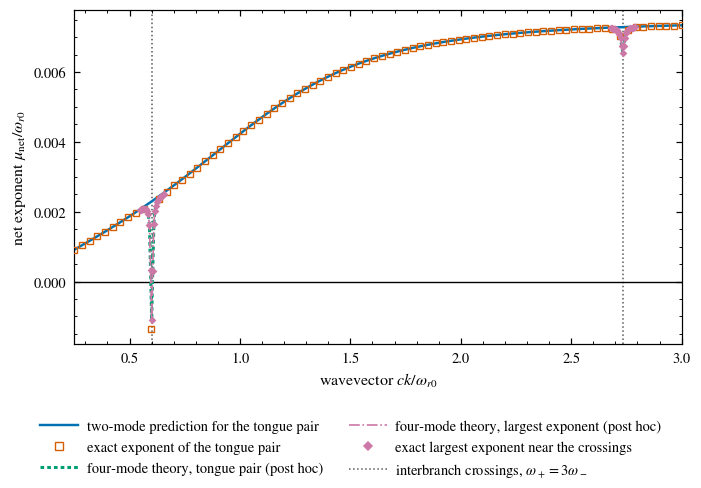

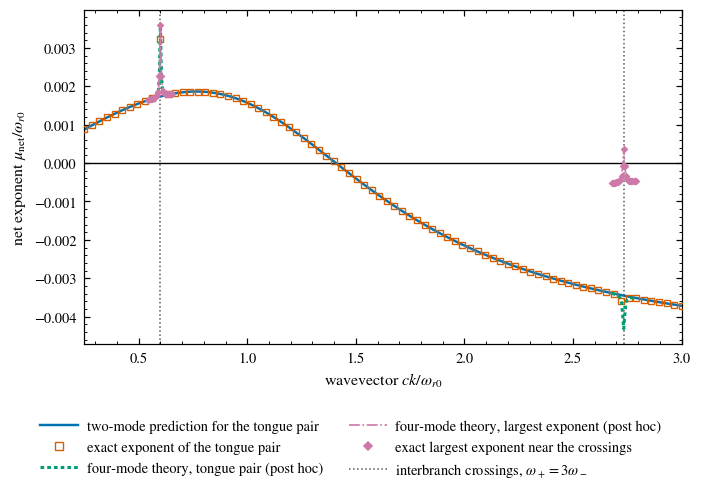

In [24]:
def rate_figure(channel, stem):
    c = next(x for x in scan if x["channel"] == channel and x["gamma"] == 0.01 and x["m"] == 0.05)
    fig, ax = fs.new_figure(11.0)
    s0, s1, s2, s3 = fs.style(0), fs.style(1), fs.style(2), fs.style(3)
    kk = np.linspace(0.25, 3.0, 600)
    ax.plot(kk, [L.net_rate(k, 0.05, 0.01, channel)[0] for k in kk], color=s0["color"], lw=1.6, zorder=2)
    ax.plot(c["k"], c["mu_pair"], s1["marker"], color=s1["color"], linestyle="none", markersize=4.2,
            markerfacecolor="none", markeredgewidth=0.9, zorder=3)
    for ks in K_STAR:
        sel = sorted((r for r in slices if r["crossing"] == ks and r["channel"] == channel
                      and r["gamma"] == 0.01 and r["m"] == 0.05), key=lambda r: r["k"])
        ksl = [r["k"] for r in sel]
        ax.plot(ksl, [r["mu_four_mode"] for r in sel], color=s2["color"], linestyle=(0, (1.2, 1.0)), lw=2.0, zorder=4)
        ax.plot(ksl, [r["four_mode_exponents"][0] for r in sel], color=s3["color"], linestyle="-.", lw=1.1, zorder=5)
        ax.plot(ksl, [r["exponents"][0] for r in sel], s3["marker"], color=s3["color"], linestyle="none",
                markersize=2.6, zorder=6)
        ax.axvline(ks, color=fs.GREY, linestyle=":", lw=1.0, zorder=1)
    ax.axhline(0.0, color="black", lw=0.9, zorder=1)
    handles = [fs.line_handle("two-mode prediction for the tongue pair", color=s0["color"], lw=1.6),
               fs.line_handle("exact exponent of the tongue pair", color=s1["color"], marker=s1["marker"],
                              linestyle="none", markersize=5.0, markerfacecolor="none", markeredgewidth=0.9),
               fs.line_handle("four-mode theory, tongue pair (post hoc)", color=s2["color"],
                              linestyle=(0, (1.2, 1.0)), lw=2.0),
               fs.line_handle("four-mode theory, largest exponent (post hoc)", color=s3["color"],
                              linestyle="-.", lw=1.1),
               fs.line_handle("exact largest exponent near the crossings", color=s3["color"], marker=s3["marker"],
                              linestyle="none", markersize=3.5),
               fs.line_handle(r"interbranch crossings, $\omega_+ = 3\omega_-$", color=fs.GREY, linestyle=":", lw=1.0)]
    ax.set_xlim(0.25, 3.0)
    ax.set_xlabel(r"wavevector $ck/\omega_{r0}$")
    ax.set_ylabel(r"net exponent $\mu_{\mathrm{net}}/\omega_{r0}$")
    fs.legend_below(fig, handles, ncol=2)
    show(fig, stem)


rate_figure("wr2", "f05_rates_resonance_channel")
rate_figure("wp2", "f06_rates_plasma_channel")

## 13. Upper polariton branch (post hoc)

The two-mode formula with $|F|$ is tested on the upper branch, $\Omega = 2\omega_+(k)$, on 60 wavevectors for three parameter sets per channel. Points with $|\mu_{\rm pred}| \ge 10^{-4}$ are confirmatory, as in Sec. 11.

In [25]:
K_UP = np.linspace(0.25, 3.0, 60)
upper, rel_up, liou_up = [], [], []
for channel in ("wr2", "wp2"):
    for gamma, m in ((1e-3, 0.02), (1e-2, 0.05), (3e-2, 0.05)):
        rows = []
        for k in K_UP:
            pred, w, F, K = L.net_rate(k, m, gamma, channel, branch="upper")
            M, T = L.monodromy(k, gamma, m, 2.0 * w, channel)
            mu_pair = L.tongue_pair(M, T)[0]
            liou_up.append(L.liouville_error(M, gamma, T))
            rows.append((k, w, F, K, pred, mu_pair))
            if abs(pred) >= 1e-4:
                rel_up.append(abs(mu_pair - pred) / abs(pred))
        a = np.array(rows)
        upper.append({"channel": channel, "gamma": gamma, "m": m,
                      **{name: a[:, i] for i, name in enumerate(("k", "omega", "F", "K", "mu_pred", "mu_pair"))}})
rel_up = np.array(rel_up)
up = {"n_points": len(rel_up), "median_rel": np.median(rel_up), "worst_rel": rel_up.max(),
      "max_liouville_error": max(liou_up), "F_wp2_negative_everywhere": all(np.all(c["F"] < 0) for c in upper if c["channel"] == "wp2")}
save_json("upper_branch.json", {"k_grid": K_UP, **up, "combinations": upper})
summary["upper"] = up
for key, value in up.items():
    print(f"{key:26s} {value}")

n_points                   337
median_rel                 2.3258572090033183e-05
worst_rel                  0.0001728710634662433
max_liouville_error        4.160560784782774e-12
F_wp2_negative_everywhere  True


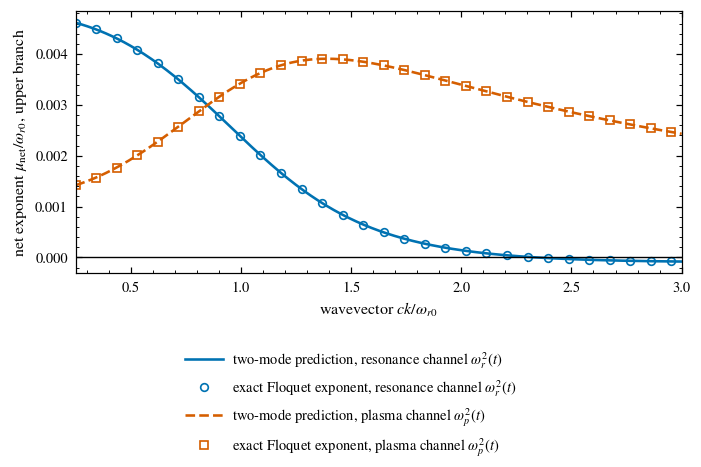

In [26]:
fig, ax = fs.new_figure(10.5)
handles = []
names = {"wr2": r"resonance channel $\omega_r^2(t)$", "wp2": r"plasma channel $\omega_p^2(t)$"}
kk = np.linspace(0.25, 3.0, 400)
for i, channel in enumerate(("wr2", "wp2")):
    c = next(x for x in upper if x["channel"] == channel and x["gamma"] == 0.01)
    st = fs.style(i)
    ax.plot(kk, [L.net_rate(k, 0.05, 0.01, channel, branch="upper")[0] for k in kk], color=st["color"],
            linestyle=st["linestyle"], lw=1.7)
    ax.plot(c["k"][::2], c["mu_pair"][::2], st["marker"], color=st["color"], linestyle="none", markersize=5.0,
            markerfacecolor="none", markeredgewidth=1.1)
    handles += [fs.line_handle(f"two-mode prediction, {names[channel]}", color=st["color"],
                               linestyle=st["linestyle"], lw=1.7),
                fs.line_handle(f"exact Floquet exponent, {names[channel]}", color=st["color"],
                               marker=st["marker"], linestyle="none", markersize=5.0, markerfacecolor="none",
                               markeredgewidth=1.1)]
ax.axhline(0.0, color="black", lw=0.9)
ax.set_xlim(0.25, 3.0)
ax.set_xlabel(r"wavevector $ck/\omega_{r0}$")
ax.set_ylabel(r"net exponent $\mu_{\mathrm{net}}/\omega_{r0}$, upper branch")
fs.legend_below(fig, handles, ncol=2)
show(fig, "f07_upper_branch")

## 14. The rate ceiling

Three tests, in increasing generality.

1. **Scan class (nonperturbative).** For all 32 combinations of the registered scan, including $m = 0.1$, the gain is reconstructed as $\mu_{\rm pair} + \gamma K$ and compared with the ceiling $m\omega_-/4$.
2. **Analytic margin across media (post hoc).** $1 - |F|$ is evaluated on 300 wavevectors $k \in [0.05, 6]$ for five media, $\omega_{p0}/\omega_{r0} \in \{0.8, 1, 1.5, 2, 3\}$, both branches and both channels, and the largest plasma-channel participation is compared with its closed form (Sec. 9.4). By the branch forms the plasma-channel margin is the same on both branches, and the resonance-channel margins of the two branches add up to one.
3. **Exact checks across media (post hoc).** Eight exact Floquet computations at $\gamma = 0.005$, $m = 0.02$ in media and on branches outside the registered scan.

In [27]:
scan_margin = min(np.min(c["m"] * c["omega"] / 4.0 - (c["mu_pair"] + c["gamma"] * c["K"])) for c in scan)
closest = min(scan, key=lambda c: np.min(c["m"] * c["omega"] / 4.0 - (c["mu_pair"] + c["gamma"] * c["K"])))

MEDIA = (0.64, 1.0, 2.25, 4.0, 9.0)
K_CEIL = np.linspace(0.05, 6.0, 300)
analytic, max_F_plasma = [], []
for wp2 in MEDIA:
    for branch in ("lower", "upper"):
        pf = L.participation(L.polariton_omega(K_CEIL, branch, 1.0, wp2), 1.0, wp2)
        for channel in ("wr2", "wp2"):
            margin_c = 1.0 - np.abs(pf["F_" + channel])
            j = int(np.argmin(margin_c))
            analytic.append({"wp0": math.sqrt(wp2), "branch": branch, "channel": channel,
                             "min_margin": margin_c[j], "k_at_min": K_CEIL[j]})
    # largest plasma-channel participation over k against its closed form
    kk = np.linspace(0.0, 6.0, 60001)
    F_max = np.abs(L.participation(L.polariton_omega(kk, "lower", 1.0, wp2), 1.0, wp2)["F_wp2"]).max()
    wp0 = math.sqrt(wp2)
    max_F_plasma.append({"wp0": wp0, "max_abs_F": F_max,
                         "closed_form": wp0 / 2.0 if wp0 <= 1.0 else wp2 / (1.0 + wp2)})
lowest = min(analytic, key=lambda r: r["min_margin"])

checks = []
for wp2, branch, channel, k in ((0.64, "lower", "wr2", 1.0), (0.64, "lower", "wp2", 0.6),
                                (0.64, "upper", "wp2", 1.0), (9.0, "lower", "wp2", 0.5),
                                (9.0, "upper", "wp2", 0.2), (9.0, "upper", "wr2", 1.0),
                                (4.0, "lower", "wr2", 2.0), (2.25, "upper", "wr2", 0.5)):
    gamma, m = 0.005, 0.02
    w = L.polariton_omega(k, branch, 1.0, wp2)
    pf = L.participation(w, 1.0, wp2)
    M, T = L.monodromy(k, gamma, m, 2.0 * w, channel, wr2=1.0, wp2=wp2)
    gain = L.tongue_pair(M, T)[0] + gamma * pf["K"]
    checks.append({"wp2": wp2, "branch": branch, "channel": channel, "k": k, "F": pf["F_" + channel],
                   "gain": gain, "ceiling": m * w / 4.0, "margin": m * w / 4.0 - gain,
                   "liouville_error": L.liouville_error(M, gamma, T)})
ceiling = {"scan_min_margin": scan_margin,
           "scan_min_margin_at": {"channel": closest["channel"], "gamma": closest["gamma"], "m": closest["m"]},
           "analytic_points": len(MEDIA) * 2 * 2 * len(K_CEIL), "analytic_min_margin": lowest["min_margin"],
           "analytic_min_at": lowest, "analytic": analytic, "max_abs_F_plasma": max_F_plasma, "exact_checks": checks,
           "exact_min_margin": min(c["margin"] for c in checks)}
save_json("ceiling.json", ceiling)
summary["ceiling"] = {k: v for k, v in ceiling.items() if k not in ("exact_checks", "analytic")}
assert scan_margin > 0 and ceiling["analytic_min_margin"] > 0 and ceiling["exact_min_margin"] > 0
print(f"scan class: minimum margin {scan_margin:+.2e} at {ceiling['scan_min_margin_at']}")
print(f"analytic: {ceiling['analytic_points']} points, minimum 1 - |F| = {lowest['min_margin']:.2e} "
      f"({lowest['channel']}, {lowest['branch']} branch, wp0 = {lowest['wp0']:.1f}, k = {lowest['k_at_min']:.2f})")
print(f"exact checks: minimum margin {ceiling['exact_min_margin']:+.2e}")
for r in max_F_plasma:
    print(f"wp0/wr0 = {r['wp0']:.1f}: largest |F| of the plasma channel {r['max_abs_F']:.6f}, closed form {r['closed_form']:.6f}")
assert all(abs(r["max_abs_F"] - r["closed_form"]) < 1e-8 for r in max_F_plasma)

scan class: minimum margin +2.01e-05 at {'channel': 'wr2', 'gamma': 0.01, 'm': 0.01}
analytic: 6000 points, minimum 1 - |F| = 5.03e-04 (wr2, lower branch, wp0 = 0.8, k = 6.00)
exact checks: minimum margin +9.20e-05
wp0/wr0 = 0.8: largest |F| of the plasma channel 0.400000, closed form 0.400000
wp0/wr0 = 1.0: largest |F| of the plasma channel 0.500000, closed form 0.500000
wp0/wr0 = 1.5: largest |F| of the plasma channel 0.692308, closed form 0.692308
wp0/wr0 = 2.0: largest |F| of the plasma channel 0.800000, closed form 0.800000
wp0/wr0 = 3.0: largest |F| of the plasma channel 0.900000, closed form 0.900000


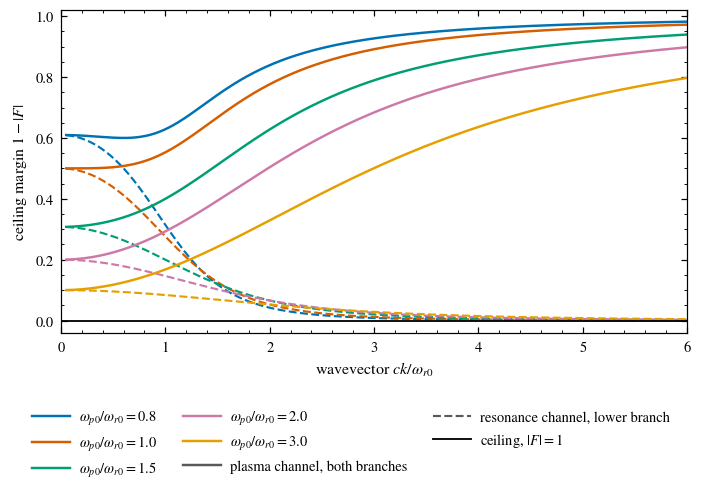

In [28]:
fig, ax = fs.new_figure(11.0)
kk = np.linspace(0.05, 6.0, 400)
handles = []
for i, wp2 in enumerate(MEDIA):
    color = fs.COLORS[i]
    lower = L.participation(L.polariton_omega(kk, "lower", 1.0, wp2), 1.0, wp2)
    ax.plot(kk, 1.0 - np.abs(lower["F_wp2"]), color=color, linestyle="-", lw=1.6)
    ax.plot(kk, 1.0 - lower["F_wr2"], color=color, linestyle="--", lw=1.4)
    handles.append(fs.line_handle(rf"$\omega_{{p0}}/\omega_{{r0}} = {math.sqrt(wp2):.1f}$", color=color, lw=1.6))
ax.axhline(0.0, color="black", lw=1.2)
handles += [fs.line_handle("plasma channel, both branches", color=fs.GREY, lw=1.6),
            fs.line_handle("resonance channel, lower branch", color=fs.GREY, lw=1.4, linestyle="--"),
            fs.line_handle(r"ceiling, $|F| = 1$", color="black", lw=1.2)]
ax.set_xlim(0.0, 6.0)
ax.set_ylim(-0.04, 1.02)
ax.set_xlabel(r"wavevector $ck/\omega_{r0}$")
ax.set_ylabel(r"ceiling margin $1 - |F|$")
fs.legend_below(fig, handles, ncol=3)
show(fig, "f08_ceiling_margin")

## 15. Thresholds and the growth inequality (H4b)

### 15.1 Sign structure of the net exponent

At $\gamma = 0.01$ and $m = 0.02$ the resonance-channel threshold $m_c = 0.02\,\omega_-$ lies below $m$ at every wavevector, so that channel should amplify across the whole grid. The plasma channel should amplify only where $m > 2\gamma\omega/(\omega_{r0}^2 - \omega^2)$, i.e. below the root $\omega_c$ of $m\omega^2 + 2\gamma\omega - m = 0$.

In [29]:
c_r = next(x for x in scan if x["channel"] == "wr2" and x["gamma"] == 0.01 and x["m"] == 0.02)
c_p = next(x for x in scan if x["channel"] == "wp2" and x["gamma"] == 0.01 and x["m"] == 0.02)
omega_c = (-0.01 + math.sqrt(0.01**2 + 0.02**2)) / 0.02
thresholds = {"resonance_positive": int((c_r["mu_pair"] > 0).sum()), "n_grid": len(c_r["k"]),
              "plasma_positive": int((c_p["mu_pair"] > 0).sum()), "omega_c": omega_c,
              "plasma_predicted_positive": int((c_p["omega"] < omega_c).sum()),
              "sign_agreement_plasma": bool(np.all((c_p["mu_pair"] > 0) == (c_p["omega"] < omega_c)))}
summary["thresholds"] = thresholds
for key, value in thresholds.items():
    print(f"{key:28s} {value}")

resonance_positive           80
n_grid                       80
plasma_positive              19
omega_c                      0.6180339887498948
plasma_predicted_positive    19
sign_agreement_plasma        True


### 15.2 H4b: the integrated growth inequality

Along each trajectory we integrate the right-hand side $R(t)$ of the growth inequality together with the field and form $g(t) = \int_0^t R\,dt' - \ln[W(t)/W(0)]$. The inequality holds on every sub-interval exactly when $g$ never decreases, so the reported violation is $\max_{t_i \le t_j}[g(t_i) - g(t_j)]$ over 2001 samples of two periods. Because $|d\ln\omega^2/dt|$ has kinks where the modulation turns around, the integration is restarted at each kink so that every segment is smooth. Where the modulation term already has the sign of its bound, the inequality is an equality, so a correct integration returns a violation at the level of the integration error, not exactly zero. The test covers all 32 scan combinations at $k \in \{0.5, 1.5, 2.5\}$ with $\Omega = 2\omega_-(k)$ and two initial states, plus simultaneous modulation of both channels with a relative phase.

In [30]:
U0 = ((1.0, 0.3 + 0.2j, 0.1, 0.05j), (0.2, 1.0, -0.4j, 0.3))
cases = []
for channel in ("wr2", "wp2"):
    for gamma in GAMMAS:
        for m in MODS:
            for k in (0.5, 1.5, 2.5):
                mod = {"mr": m} if channel == "wr2" else {"mp": m}
                cases += [{"channel": channel, "gamma": gamma, "m": m, "k": k, "u0": i, "mod": mod}
                          for i in range(len(U0))]
for gamma in GAMMAS:
    for m in (0.02, 0.1):
        cases.append({"channel": "both", "gamma": gamma, "m": m, "k": 1.5, "u0": 0,
                      "mod": {"mr": m, "mp": m, "phase": math.pi / 3}})


def violation(case, **kw):
    Om = 2.0 * L.polariton_omega(case["k"])
    return L.growth_inequality_violation(case["k"], case["gamma"], Om, u0=U0[case["u0"]], **case["mod"], **kw)


t0 = time.perf_counter()
h4b_rows = [{**case, "violation": violation(case)} for case in cases]
worst = max(h4b_rows, key=lambda r: r["violation"])
tolerance_scaling = {rt: violation(worst, rtol=rt, atol=rt * 1e-2) for rt in (1e-9, 1e-11, 1e-13)}
h4b = {"n_trajectories": len(h4b_rows), "max_violation": worst["violation"],
       "worst_case": {k: worst[k] for k in ("channel", "gamma", "m", "k", "u0")},
       "tolerance_scaling": tolerance_scaling, "passes": worst["violation"] < TOL_NUM}
save_json("thresholds_growth_inequality.json", {"thresholds": thresholds, **h4b, "rows": h4b_rows})
summary["H4b"] = h4b
assert h4b["passes"]
print(f"{len(h4b_rows)} trajectories in {time.perf_counter() - t0:.0f} s; largest violation "
      f"{worst['violation']:.2e} at {h4b['worst_case']}")
for rt, v in tolerance_scaling.items():
    print(f"  rtol = {rt:.0e}: violation {v:.2e}")

200 trajectories in 11 s; largest violation 8.27e-11 at {'channel': 'wp2', 'gamma': 0.03, 'm': 0.01, 'k': 2.5, 'u0': 1}
  rtol = 1e-09: violation 6.91e-09
  rtol = 1e-11: violation 8.27e-11
  rtol = 1e-13: violation 7.63e-13


The residual violation scales linearly with the integration tolerance, so it is integration error and not a property of the trajectories.

## 16. H4c: gap width and net rate along the resonance path

The path $P^*$ (plasma channel, $m = 0.05$, $\gamma = 0.01$) steps the lower-branch frequency toward the resonance, $1 - \omega/\omega_{r0}$ from 0.40 to 0.01 in 12 logarithmic steps. At each step the drive is fixed at $\Omega = 2\omega$ and the wavevector is scanned on 121 points around the tongue center $k_c = \omega\sqrt{\varepsilon(\omega)}$. The scan window is $k_c \pm \max(8G/v_g,\ 0.03k_c)$, where $G = |F|m\omega/4$ is the two-mode gain and $v_g = d\omega/dk$ the group velocity, so that the expected gap occupies a fixed fraction of the window. The width is measured with the detector of Sec. 9.6. At every step the scan is repeated on 241 points (doubled resolution), and the width is recomputed with detector thresholds $10^{-11}$ and $10^{-7}$. Two rates are recorded: the registered metric, the largest exponent of the medium over the scan window, which can belong to any of the four modes, and the exponent of the tongue pair at the tongue center, which is the quantity predicted by the two-mode theory.

In [31]:
def group_velocity(w):
    A = L.WR2 - w * w
    eps = 1.0 + L.WP2 / A
    dk_dw = math.sqrt(eps) + w * (2.0 * w * L.WP2 / A**2) / (2.0 * math.sqrt(eps))
    return 1.0 / dk_dw


GAMMA_P, M_P = 0.01, 0.05
t0 = time.perf_counter()
path = []
for d in np.geomspace(0.40, 0.01, 12):
    w = 1.0 - d
    kc = w * math.sqrt(1.0 + L.WP2 / (L.WR2 - w * w))
    pred, _, F, K = L.net_rate(kc, M_P, GAMMA_P, "wp2")
    gain = abs(F) * M_P * w / 4.0
    half = max(8.0 * gain / group_velocity(w), 0.03 * kc)
    step = {"detuning": d, "omega": w, "k_center": kc, "group_velocity": group_velocity(w),
            "mu_pred_center": pred, "F": F, "K": K, "m_c": L.threshold(w, "wp2", GAMMA_P),
            "mu_pair_center": L.tongue_pair(*L.monodromy(kc, GAMMA_P, M_P, 2.0 * w, "wp2"))[0]}
    for n in (121, 241):
        kk = np.linspace(max(kc - half, 0.05), kc + half, n)
        res, liou = [], []
        for k in kk:
            M, T = L.monodromy(k, GAMMA_P, M_P, 2.0 * w, "wp2")
            res.append(L.tongue_pair(M, T))
            liou.append(L.liouville_error(M, GAMMA_P, T))
        res = np.array(res)
        step[f"max_liouville_error_{n}"] = max(liou)
        dk = kk[1] - kk[0]
        step[f"dk_{n}"] = dk
        step[f"width_{n}"] = (res[:, 1] > 1e-9).sum() * dk
        step[f"max_mu_net_{n}"] = res[:, 2].max()
        if n == 121:
            step["width_threshold_1e-11"] = (res[:, 1] > 1e-11).sum() * dk
            step["width_threshold_1e-7"] = (res[:, 1] > 1e-7).sum() * dk
            k_max = kk[int(np.argmax(res[:, 2]))]
            step["k_at_max_mu_net"] = k_max
            step["beat_ratio_at_max"] = (L.polariton_omega(k_max, "upper") - L.polariton_omega(k_max)) / (2.0 * w)
    path.append(step)
print(f"path P*: {time.perf_counter() - t0:.0f} s")
for s in path:
    print(f"detuning {s['detuning']:.4f}: width {s['width_121']:.4f} (241 points: {s['width_241']:.4f}); largest "
          f"exponent {s['max_mu_net_121']:+.2e} at (w+ - w-)/Om = {s['beat_ratio_at_max']:.3f}; tongue pair at the "
          f"center {s['mu_pair_center']:+.3e}, two-mode {s['mu_pred_center']:+.3e}; m_c = {s['m_c']:.3f}")

path P*: 80 s
detuning 0.4000: width 0.0106 (241 points: 0.0106); largest exponent +1.83e-03 at (w+ - w-)/Om = 0.679; tongue pair at the center +1.829e-03, two-mode +1.829e-03; m_c = 0.019
detuning 0.2860: width 0.0153 (241 points: 0.0153); largest exponent +1.33e-03 at (w+ - w-)/Om = 0.563; tongue pair at the center +1.328e-03, two-mode +1.328e-03; m_c = 0.029
detuning 0.2045: width 0.0209 (241 points: 0.0209); largest exponent +4.03e-04 at (w+ - w-)/Om = 0.541; tongue pair at the center +4.029e-04, two-mode +4.029e-04; m_c = 0.043
detuning 0.1463: width 0.0275 (241 points: 0.0275); largest exponent -6.73e-04 at (w+ - w-)/Om = 0.574; tongue pair at the center -6.735e-04, two-mode -6.735e-04; m_c = 0.063
detuning 0.1046: width 0.0351 (241 points: 0.0351); largest exponent -1.04e-03 at (w+ - w-)/Om = 0.707; tongue pair at the center -1.686e-03, two-mode -1.686e-03; m_c = 0.090
detuning 0.0748: width 0.0441 (241 points: 0.0441); largest exponent -7.14e-04 at (w+ - w-)/Om = 0.841; tongue 

In [32]:
first, last = path[0], path[-1]
ratio = last["width_121"] / first["width_121"]
ratio_sigma = ratio * math.hypot(first["dk_121"] / first["width_121"], last["dk_121"] / last["width_121"])
h4c = {"width_first": first["width_121"], "width_last": last["width_121"],
       "dk_first": first["dk_121"], "dk_last": last["dk_121"],
       "width_ratio": ratio, "width_ratio_sigma": ratio_sigma,
       "rate_first": first["max_mu_net_121"], "rate_last": last["max_mu_net_121"],
       "rate_factor": last["max_mu_net_121"] / first["max_mu_net_121"],
       "pred_first": first["mu_pred_center"], "pred_last": last["mu_pred_center"],
       "pair_first": first["mu_pair_center"], "pair_last": last["mu_pair_center"],
       "max_abs_pair_minus_two_mode": max(abs(s["mu_pair_center"] - s["mu_pred_center"]) for s in path),
       "max_rel_pair_minus_two_mode": max(abs(s["mu_pair_center"] - s["mu_pred_center"]) / abs(s["mu_pred_center"])
                                          for s in path),
       "positive_after_sign_change": [{"detuning": s["detuning"], "max_mu_net": s["max_mu_net_121"],
                                       "beat_ratio": s["beat_ratio_at_max"]}
                                      for i, s in enumerate(path)
                                      if s["max_mu_net_121"] > 0 and any(t["max_mu_net_121"] < 0 for t in path[:i])],
       "m_c_first": first["m_c"], "m_c_last": last["m_c"],
       "max_liouville_error": max(max(s["max_liouville_error_121"], s["max_liouville_error_241"]) for s in path),
       "max_width_change_doubled_grid": max(abs(s["width_241"] - s["width_121"]) / s["dk_121"] for s in path),
       "max_width_change_threshold": max(max(abs(s["width_threshold_1e-11"] - s["width_121"]),
                                             abs(s["width_threshold_1e-7"] - s["width_121"])) / s["dk_121"]
                                         for s in path)}
h4c["width_criterion"] = ratio > 3.0
h4c["rate_criterion"] = h4c["rate_factor"] < 1.5
save_json("resonance_path.json", {**h4c, "steps": path})
summary["H4c"] = h4c
for key, value in h4c.items():
    print(f"{key:30s} {value}")

width_first                    0.010606601717798592
width_last                     0.13822594727085136
dk_first                       0.0007071067811865728
dk_last                        0.00921506315139009
width_ratio                    13.032067286819954
width_ratio_sigma              1.2286750868519682
rate_first                     0.001829420881897112
rate_last                      -8.463468020863203e-05
rate_factor                    -0.0462630994573899
pred_first                     0.0018292682926829274
pred_last                      -0.00465135939869457
pair_first                     0.001829420881897112
pair_last                      -0.00465164342372943
max_abs_pair_minus_two_mode    5.579033494395105e-07
max_rel_pair_minus_two_mode    0.0001746890058883286
positive_after_sign_change     [{'detuning': np.float64(0.05348217823095263), 'max_mu_net': np.float64(0.00020960816229730135), 'beat_ratio': np.float64(0.9999267457865372)}, {'detuning': np.float64(0.03824434872406297), 

**Outcome.** The width criterion and the rate criterion are both met. The tongue pair follows the two-mode prediction along the whole path and ends far below threshold, where $m_c$ approaches 1 against $m = 0.05$. Near resonance the largest exponent of the medium belongs to a weakly damped mode of the upper branch, and at two intermediate steps it is positive because the scan window contains the interbranch crossing $k^\ast = 2.733$, where the hybrid mode of Sec. 12 amplifies; the printed ratio $(\omega_+ - \omega_-)/\Omega \approx 1$ at the maximum identifies these steps.

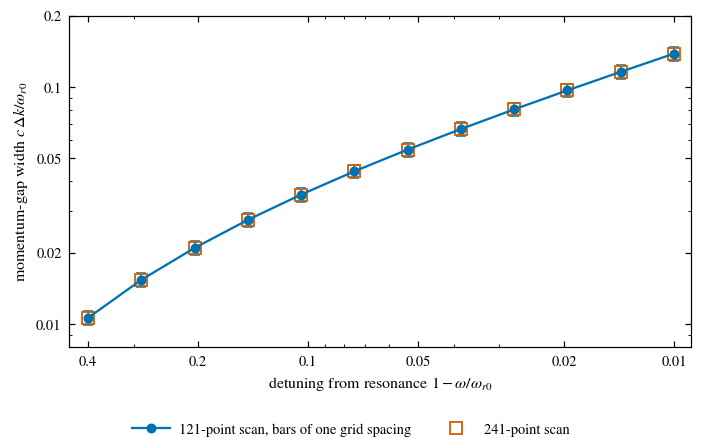

In [33]:
det = np.array([s["detuning"] for s in path])
fig, ax = fs.new_figure(10.0)
s0, s1 = fs.style(0), fs.style(1)
ax.errorbar(det, [s["width_121"] for s in path], yerr=[s["dk_121"] for s in path], color=s0["color"],
            marker=s0["marker"], linestyle="-", markersize=5.5, capsize=3.0, elinewidth=1.0)
ax.plot(det, [s["width_241"] for s in path], s1["marker"], color=s1["color"], linestyle="none",
        markersize=7.5, markerfacecolor="none", markeredgewidth=1.2)
handles = [fs.line_handle("121-point scan, bars of one grid spacing", color=s0["color"], marker=s0["marker"],
                          markersize=5.5),
           fs.line_handle("241-point scan", color=s1["color"], marker=s1["marker"], linestyle="none",
                          markersize=7.5, markerfacecolor="none", markeredgewidth=1.2)]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.4], labels=["0.01", "0.02", "0.05", "0.1", "0.2", "0.4"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2], labels=["0.01", "0.02", "0.05", "0.1", "0.2"])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(0.008, 0.2)
ax.set_xlim(0.45, 0.009)
ax.set_xlabel(r"detuning from resonance $1 - \omega/\omega_{r0}$")
ax.set_ylabel(r"momentum-gap width $c\,\Delta k/\omega_{r0}$")
fs.legend_below(fig, handles, ncol=2)
show(fig, "f09_gap_width_path")

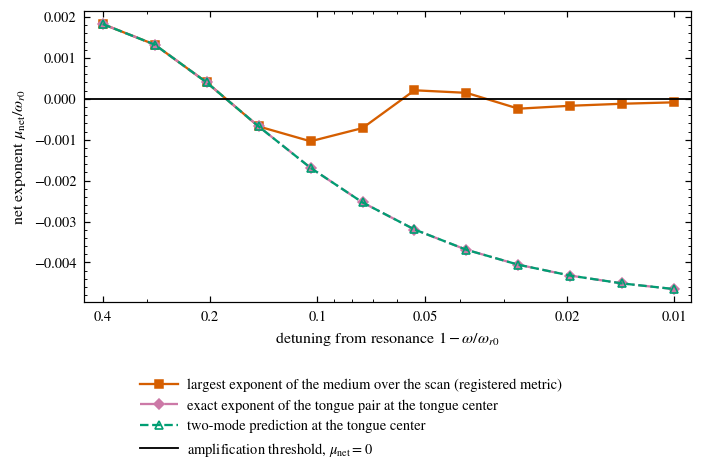

In [34]:
fig, ax = fs.new_figure(10.5)
s1, s2, s3 = fs.style(1), fs.style(2), fs.style(3)
ax.plot(det, [s["max_mu_net_121"] for s in path], color=s1["color"], marker=s1["marker"], linestyle="-",
        markersize=5.5)
ax.plot(det, [s["mu_pair_center"] for s in path], color=s3["color"], marker=s3["marker"], linestyle="-.",
        markersize=5.0)
ax.plot(det, [s["mu_pred_center"] for s in path], color=s2["color"], marker=s2["marker"], linestyle="--",
        markersize=5.0, markerfacecolor="none", markeredgewidth=1.1)
ax.axhline(0.0, color="black", lw=1.2)
handles = [fs.line_handle("largest exponent of the medium over the scan (registered metric)", color=s1["color"],
                          marker=s1["marker"], markersize=5.5),
           fs.line_handle("exact exponent of the tongue pair at the tongue center", color=s3["color"],
                          marker=s3["marker"], linestyle="-.", markersize=5.0),
           fs.line_handle("two-mode prediction at the tongue center", color=s2["color"], marker=s2["marker"],
                          linestyle="--", markersize=5.0, markerfacecolor="none", markeredgewidth=1.1),
           fs.line_handle(r"amplification threshold, $\mu_{\mathrm{net}} = 0$", color="black", lw=1.2)]
ax.set_xscale("log")
ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.4], labels=["0.01", "0.02", "0.05", "0.1", "0.2", "0.4"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(0.45, 0.009)
ax.set_xlabel(r"detuning from resonance $1 - \omega/\omega_{r0}$")
ax.set_ylabel(r"net exponent $\mu_{\mathrm{net}}/\omega_{r0}$")
fs.legend_below(fig, handles, ncol=1)
show(fig, "f10_net_rate_path")

## 17. Summary of results

The table lists every registered criterion with its outcome, followed by the quantities quoted in the article. All values are recomputed above; `results/summary.json` holds them in machine-readable form.

In [35]:
summary["audits"] = {
    "wronskian": max(summary["H1"]["max_wronskian_error"], summary["extended"]["max_wronskian_error"]),
    "liouville": max(summary["H4a"]["max_liouville_error"], summary["upper"]["max_liouville_error"],
                     max(r["liouville_error"] for r in slices), summary["H4c"]["max_liouville_error"],
                     max(c["liouville_error"] for c in ceiling["exact_checks"]))}
summary["runtime_minutes"] = (time.perf_counter() - t_start) / 60.0
save_json("summary.json", {k: v for k, v in summary.items() if k != "runtime_minutes"})

S = summary
outcomes = [
    ("H1", "bound holds on the protocol ensemble", f"{S['H1']['violations']} violations in {S['H1']['n_monodromies']} monodromies", "pass"),
    ("H2", r"harmonic efficiency within 2% of $\pi/4$ ($\delta \le 0.02$)", f"largest deviation {100 * S['H2']['registered_max_deviation']:.2f}%", "pass"),
    ("H3", "two-switch saturation at least 0.99", f"minimum {S['H3']['min_final_saturation']:.5f}", "pass"),
    ("H4a", "two-mode rate within 10% across the grid", f"{S['H4a']['n_fail_registered']} of {S['H4a']['n_points']} points fail", "fail as registered"),
    ("H4b", "integrated growth inequality", f"largest violation {S['H4b']['max_violation']:.1e}", "pass"),
    ("H4c", "width factor > 3, rate factor < 1.5", f"{S['H4c']['width_ratio']:.1f} and {S['H4c']['rate_factor']:.2f}", "pass"),
]
table = ["| Criterion | Statement | Measured | Outcome |", "|---|---|---|---|"]
table += [f"| {a} | {b} | {c} | {d} |" for a, b, c, d in outcomes]
display(Markdown("\n".join(table)))

headline = [
    ("Protocol ensemble: worst margin $\\mu T - \\mathrm{TV}/4$", f"{S['H1']['worst_margin_class_a']:.3e}"),
    ("Protocol ensemble: best saturation (log-Fourier)", f"{S['H1']['best_saturation_class_a']:.4f}"),
    ("Extended ensemble: profiles / monodromies", f"{S['extended']['n_profiles']} / {S['extended']['n_monodromies']}"),
    ("Extended ensemble: largest exponent saturation", f"{S['extended']['max_saturation']:.4f}"),
    ("Extended ensemble: largest energy-norm saturation", f"{S['extended']['max_norm_saturation']:.4f}"),
    ("Class maxima: log-Fourier / sinusoid / two-level",
     " / ".join(f"{S['extended']['class_max_saturation'][c]:.3f}" for c in CLASSES)),
    ("Sudden switching: largest $|1 - \\text{saturation}|$", f"{S['H3']['sudden_max_abs_deficit']:.1e}"),
    ("Two-switch saturation at $w/T = 0.02$ and 0.005 ($\\varepsilon_2/\\varepsilon_1 = 2$)",
     f"{S['H3']['saturation_by_ramp'][2.0][0]:.4f} and {S['H3']['saturation_by_ramp'][2.0][-1]:.4f}"),
    ("Deficit scaling exponent in $w/T$ (three contrasts)",
     ", ".join(f"{v:.2f}" for v in S['H3']['deficit_slope'].values())),
    ("Optimizer spread over seeds 7, 8, 9", f"{S['H3']['seed_spread']:.1e}"),
    ("Step component of $\\mu T$ without a cap / with the production cap",
     f"{S['H3']['uncertainty']['step_component_uncapped']:.1e} / {S['H3']['uncertainty']['step_component_production']:.1e}"),
    ("Tolerance component of $\\mu T$", f"{S['H3']['uncertainty']['tolerance_component']:.1e}"),
    ("$\\sigma_{\\rm solver}$ and $\\mathrm{tol}_{\\rm num}$", f"{S['sigma_solver']:.1e} and {S['tol_num']:.4e}"),
    ("Harmonic efficiency: largest deviation from $\\pi/4$ up to $\\delta = 0.6$", f"{100 * S['H2']['sweep_max_deviation']:.3f}%"),
    ("Lower branch away from crossings: median / 95th percentile / worst",
     f"{100 * S['H4a']['median_rel_away']:.3f}% / {100 * S['H4a']['p95_rel_away']:.2f}% / {100 * S['H4a']['worst_rel_away']:.2f}% ({S['H4a']['n_points_away']} points)"),
    ("Registered H4a: failing points and worst error", f"{S['H4a']['n_fail_registered']} and {100 * S['H4a']['worst_rel_registered']:.0f}%"),
    ("Four-mode theory on both slices: largest error of the spectrum / of the leading exponent",
     f"{S['crossings']['max_abs_spectrum']:.1e} / {S['crossings']['max_abs_leading']:.1e}"),
    ("Upper branch: median / worst relative error", f"{100 * S['upper']['median_rel']:.4f}% / {100 * S['upper']['worst_rel']:.3f}% ({S['upper']['n_points']} points)"),
    ("Largest plasma-channel participation, $\\omega_{p0}/\\omega_{r0} = 0.8$ and 3",
     f"{S['ceiling']['max_abs_F_plasma'][0]['max_abs_F']:.3f} and {S['ceiling']['max_abs_F_plasma'][-1]['max_abs_F']:.3f}"),
    ("Ceiling: scan margin / analytic minimum / exact minimum",
     f"{S['ceiling']['scan_min_margin']:.1e} / {S['ceiling']['analytic_min_margin']:.1e} / {S['ceiling']['exact_min_margin']:.1e}"),
    ("Thresholds at $\\gamma = 0.01$, $m = 0.02$: amplifying points, resonance / plasma",
     f"{S['thresholds']['resonance_positive']} / {S['thresholds']['plasma_positive']} of {S['thresholds']['n_grid']}"),
    ("Path $P^*$: width first and last", f"{S['H4c']['width_first']:.4f} and {S['H4c']['width_last']:.3f}"),
    ("Path $P^*$: width ratio", f"{S['H4c']['width_ratio']:.1f} ± {S['H4c']['width_ratio_sigma']:.1f}"),
    ("Path $P^*$: largest exponent of the medium, first and last", f"{S['H4c']['rate_first']:+.2e} and {S['H4c']['rate_last']:+.1e}"),
    ("Path $P^*$: tongue pair at the center, first and last", f"{S['H4c']['pair_first']:+.2e} and {S['H4c']['pair_last']:+.2e}"),
    ("Path $P^*$: largest relative difference, tongue pair and two-mode", f"{100 * S['H4c']['max_rel_pair_minus_two_mode']:.2f}%"),
    ("Path $P^*$: positive largest exponent after the sign change (detuning: value)",
     ", ".join(f"{x['detuning']:.3f}: {x['max_mu_net']:+.1e}" for x in S['H4c']['positive_after_sign_change']) or "none"),
    ("Audits: largest $|\\det M - 1|$ (Hill) / $|\\det M - e^{-\\gamma T}|$ (Lorentz)",
     f"{S['audits']['wronskian']:.1e} / {S['audits']['liouville']:.1e}"),
]
display(Markdown("\n".join(["| Quantity | Value |", "|---|---|"] + [f"| {a} | {b} |" for a, b in headline])))
print(f"total runtime {summary['runtime_minutes']:.1f} min; results in {RESULTS.name}/, figures in {FIGURES.name}/")

| Criterion | Statement | Measured | Outcome |
|---|---|---|---|
| H1 | bound holds on the protocol ensemble | 0 violations in 24960 monodromies | pass |
| H2 | harmonic efficiency within 2% of $\pi/4$ ($\delta \le 0.02$) | largest deviation 0.16% | pass |
| H3 | two-switch saturation at least 0.99 | minimum 0.99953 | pass |
| H4a | two-mode rate within 10% across the grid | 19 of 1842 points fail | fail as registered |
| H4b | integrated growth inequality | largest violation 8.3e-11 | pass |
| H4c | width factor > 3, rate factor < 1.5 | 13.0 and -0.05 | pass |

| Quantity | Value |
|---|---|
| Protocol ensemble: worst margin $\mu T - \mathrm{TV}/4$ | -7.715e-02 |
| Protocol ensemble: best saturation (log-Fourier) | 0.7487 |
| Extended ensemble: profiles / monodromies | 124 / 4960 |
| Extended ensemble: largest exponent saturation | 0.9968 |
| Extended ensemble: largest energy-norm saturation | 0.9987 |
| Class maxima: log-Fourier / sinusoid / two-level | 0.756 / 0.784 / 0.997 |
| Sudden switching: largest $|1 - \text{saturation}|$ | 1.8e-15 |
| Two-switch saturation at $w/T = 0.02$ and 0.005 ($\varepsilon_2/\varepsilon_1 = 2$) | 0.9933 and 0.9996 |
| Deficit scaling exponent in $w/T$ (three contrasts) | 2.00, 2.00, 1.99 |
| Optimizer spread over seeds 7, 8, 9 | 1.3e-13 |
| Step component of $\mu T$ without a cap / with the production cap | 3.7e-12 / 3.5e-14 |
| Tolerance component of $\mu T$ | 3.9e-11 |
| $\sigma_{\rm solver}$ and $\mathrm{tol}_{\rm num}$ | 1.8e-15 and 1.0000e-08 |
| Harmonic efficiency: largest deviation from $\pi/4$ up to $\delta = 0.6$ | 0.058% |
| Lower branch away from crossings: median / 95th percentile / worst | 0.006% / 0.15% / 2.71% (1707 points) |
| Registered H4a: failing points and worst error | 19 and 159% |
| Four-mode theory on both slices: largest error of the spectrum / of the leading exponent | 4.5e-05 / 1.6e-05 |
| Upper branch: median / worst relative error | 0.0023% / 0.017% (337 points) |
| Largest plasma-channel participation, $\omega_{p0}/\omega_{r0} = 0.8$ and 3 | 0.400 and 0.900 |
| Ceiling: scan margin / analytic minimum / exact minimum | 2.0e-05 / 5.0e-04 / 9.2e-05 |
| Thresholds at $\gamma = 0.01$, $m = 0.02$: amplifying points, resonance / plasma | 80 / 19 of 80 |
| Path $P^*$: width first and last | 0.0106 and 0.138 |
| Path $P^*$: width ratio | 13.0 ± 1.2 |
| Path $P^*$: largest exponent of the medium, first and last | +1.83e-03 and -8.5e-05 |
| Path $P^*$: tongue pair at the center, first and last | +1.83e-03 and -4.65e-03 |
| Path $P^*$: largest relative difference, tongue pair and two-mode | 0.02% |
| Path $P^*$: positive largest exponent after the sign change (detuning: value) | 0.053: +2.1e-04, 0.038: +1.5e-04 |
| Audits: largest $|\det M - 1|$ (Hill) / $|\det M - e^{-\gamma T}|$ (Lorentz) | 4.7e-12 / 7.9e-12 |

total runtime 23.3 min; results in results/, figures in figures/
